# Differential Expression Analysis — MSqRob (clean)

Tests for differential protein abundance between K562 and HEK293T single cells using `msqrob2`, a ridge-penalised robust mixed-effects model fitted on precursor intensities aggregated to proteins by median polish.

Two complementary analyses are run on the **same feature universe**:

1. **Integrated analysis** — all cells across all plates fitted jointly with progressively richer batch-covariate sets, showing how correcting for technical effects changes sensitivity and precision.
2. **Per-plate analysis** — each plate fitted independently (single-lab scenario), then compared back to the integrated hits.

**Notes on this version**

- The search engine is selected once through the `ENGINE` variable; all column names and paths follow from it.
- No completeness-based feature filtering is applied. The integrated models and the per-plate models therefore operate on the same protein set, so the overlap between them is a matched comparison.
- All inputs and outputs use the engine-specific `RESULTS_DIR`.

| Model | Covariates added | Captures |
|---|---|---|
| `norm`  | `medianIntensityProtein + n_proteins` | Intensity-scale normalisation |
| `plate` | `+ (1 \| plate_id)` | Plate-level batch intercept |
| `batch` | `+ (0 + comment.X.position. \| plate_id)` | Per-plate injection-position gradient |
| `all`   | `+ injection_order + (1 \| plate_id:date)` | Run order and acquisition day |

## 1. Setup

In [5]:
library(reticulate)
use_condaenv("r45_msqrob", required = TRUE)

pkgs <- c(
    "anndata", "dplyr", "tidyr", "purrr", "tibble",
    "ggplot2", "patchwork", "ggrepel", "scales",
    "msqrob2", "scp", "QFeatures", "SingleCellExperiment",
    "MsCoreUtils", "UpSetR", "lubridate", "limma"
)

cat("Package check\n"); cat(strrep("-", 40), "\n")
for (p in pkgs) {
    ok  <- requireNamespace(p, quietly = TRUE)
    ver <- if (ok) as.character(packageVersion(p)) else "MISSING"
    cat(sprintf("  %-25s %s\n", p, ver))
}
cat("\n")

suppressPackageStartupMessages({
    invisible(lapply(pkgs, library, character.only = TRUE))
})

source("../../SCI_R/plotting_utils.R")
source("../../SCI_R/msqrob_plots.R")

Package check
---------------------------------------- 
  anndata                   0.9.0
  dplyr                     1.2.1
  tidyr                     1.3.2
  purrr                     1.2.2
  tibble                    3.3.1
  ggplot2                   4.0.3
  patchwork                 1.3.2
  ggrepel                   0.9.8
  scales                    1.4.0
  msqrob2                   1.18.0
  scp                       1.20.0
  QFeatures                 1.20.0
  SingleCellExperiment      1.32.0
  MsCoreUtils               1.22.1
  UpSetR                    1.4.0
  lubridate                 1.9.5
  limma                     3.66.0



## 2. Configuration

Set `ENGINE` to switch the whole notebook between search engines. Everything else (column names, input and output paths) is derived from it.

In [6]:
# ---- Engine selection -------------------------------------------------------
ENGINE <- "Spectronaut"   # one of: "Spectronaut", "DIANN"

NOTEBOOK_DIR <- normalizePath(getwd())
ROOT_OUT     <- normalizePath(file.path(NOTEBOOK_DIR, "../../Data"))
ROOT_OUT     <- Sys.getenv("SCI_DATA_DIR", unset = ROOT_OUT)
FIGURES_ROOT <- normalizePath(file.path(NOTEBOOK_DIR, "../../Figures"))
FIGURES_ROOT <- Sys.getenv("SCI_FIGURES_DIR", unset = FIGURES_ROOT)

ROOT_IN = "/public/conode53/sam/SCI_paper/Zenodo/Data"

engine_config <- list(
    Spectronaut = list(
        anndata_in = file.path(ROOT_IN, "AnnData", "Spectronaut"),
        results    = file.path(ROOT_IN, "MSqRob", "Spectronaut"),
        fig_out    = file.path(FIGURES_ROOT, "1_Spectronaut", "Figure_6", "MSqRob"),
        pg_col     = "PG.ProteinAccessions"
    ),
    DIANN = list(
        anndata_in = file.path(ROOT_OUT, "AnnData", "DIANN", "v2.6", "second_pass", "out"),
        results    = file.path(ROOT_OUT, "MSqRob", "DIANN", "v2.6", "second_pass"),
        fig_out    = file.path(FIGURES_ROOT, "0_DIANN", "v2.6", "Figure_6", "MSqRob"),
        pg_col     = "Protein.Group"
    )
)
stopifnot(ENGINE %in% names(engine_config))
cfg_engine <- engine_config[[ENGINE]]

ANNDATA_IN    <- cfg_engine$anndata_in
RESULTS_DIR   <- cfg_engine$results
FIG_OUT       <- cfg_engine$fig_out
PG_COL        <- cfg_engine$pg_col

DEA_RDS_DIR   <- file.path(RESULTS_DIR, "DEA_results", "rds")
DEA_CSV_DIR   <- file.path(RESULTS_DIR, "DEA_results", "csv")
QF_DIR        <- file.path(RESULTS_DIR, "QFeatures")
PER_PLATE_DIR <- file.path(RESULTS_DIR, "per_plate")

for (d in c(RESULTS_DIR, DEA_RDS_DIR, DEA_CSV_DIR, QF_DIR, PER_PLATE_DIR, FIG_OUT)) {
    dir.create(d, recursive = TRUE, showWarnings = FALSE)
}

# ---- Column-name constants (make.names versions of the SDRF columns) --------
COL_CELL_TYPE   <- "source.name"
COL_PLATE       <- "plate_idx"     # lab/plate index, used for subsetting
COL_PLATE_MODEL <- "plate_id"      # raw plate id, used as random-effect grouping
COL_INSTRUMENT  <- "instrument_type"
COL_X_POS       <- "comment.X.position."
COL_DATE        <- "comment.Gradient.time._date"
COL_DATETIME    <- "comment.Gradient.time._datetime"
COL_N_PROTEINS  <- "n_proteins"
COL_MED_INT     <- "medianIntensityProtein"
COL_INJ_ORDER   <- "injection_order"

# ---- Contrast (ridge-penalised coefficients are prefixed "ridge") -----------
CONTRAST_STR    <- "ridgesource.nameK562 - ridgesource.nameHEK293T = 0"
CONTRAST_PARAMS <- c("ridgesource.nameK562", "ridgesource.nameHEK293T")
CONTRAST_LABEL  <- gsub(" = 0", "", CONTRAST_STR)
CONDITIONS      <- c("HEK293T", "K562")

# ---- Thresholds and feature-preparation parameters --------------------------
FDR_THRESHOLD   <- 0.001
FC_THRESHOLD    <- 0.5
MIN_PREC_PER_PG <- 1   # minimum precursors per protein group for aggregation

cat(sprintf("Engine      : %s\n", ENGINE))
cat(sprintf("AnnData in  : %s\n", ANNDATA_IN))
cat(sprintf("Results dir : %s\n", RESULTS_DIR))
cat(sprintf("Figures dir : %s\n", FIG_OUT))
cat(sprintf("PG column   : %s\n", PG_COL))

Engine      : Spectronaut
AnnData in  : /public/conode53/sam/SCI_paper/Zenodo/Data/AnnData/Spectronaut
Results dir : /public/conode53/sam/SCI_paper/Zenodo/Data/MSqRob/Spectronaut
Figures dir : /home/sam/SCI/SCI/Figures/1_Spectronaut/Figure_6/MSqRob
PG column   : PG.ProteinAccessions


## 3. Load data and build the SingleCellExperiment

Loads the precursor-level AnnData, applies a dataset-specific injection-order fix, restricts to the two cell types and to non-outlier cells, drops precursors that are never observed, and builds a `SingleCellExperiment`. `colData` is built with `DataFrame()` (default `check.names = TRUE`), which converts the bracketed SDRF column names to the `make.names` form used in the model formulas (for example `source name` becomes `source.name`).

In [7]:
adata_precursor <- read_h5ad(file.path(ANNDATA_IN, "adata_precursor.h5ad"))

# Precursor x cell log2 matrix (features in rows, as QFeatures expects)
int_mat <- t(as.matrix(adata_precursor$layers[["X_log2"]]))
obs     <- adata_precursor$obs
var_meta  <- adata_precursor$var
# ---- Dataset-specific fix ---------------------------------------------------
# Astral_6 is a reinjection of the Astral_3 samples and carries no gradient
# timestamps of its own, so injection_order is missing. Copy it from Astral_3
# by matching sample_name.
if (all(c("Astral_3", "Astral_6") %in% obs[[COL_PLATE]])) {
    src    <- obs[obs[[COL_PLATE]] == "Astral_3", ]
    lookup <- setNames(src$injection_order, src$sample_name)
    mask   <- obs[[COL_PLATE]] == "Astral_6" & obs$sample_name %in% names(lookup)
    obs$injection_order[mask] <- lookup[obs$sample_name[mask]]
    cat(sprintf("Copied injection_order to %d Astral_6 cells from Astral_3\n", sum(mask)))
}

# ---- Sample filter: drop completeness outliers, keep the two cell types -----
keep_samples <- !obs[["completeness_outlier"]] & obs[["source name"]] %in% CONDITIONS
obs     <- obs[keep_samples, ]
int_mat <- int_mat[, keep_samples]
cat(sprintf("Cells retained     : %d\n", sum(keep_samples)))

# ---- Feature filter: keep precursors observed in at least one retained cell -
keep_features <- rowSums(!is.na(int_mat)) > 0 & !var_meta[['Contaminant']]
int_mat  <- int_mat[keep_features, ]
var_meta <- adata_precursor$var[keep_features, ]
cat(sprintf("Precursors retained: %d\n", sum(keep_features)))

# ---- Build SingleCellExperiment ---------------------------------------------
sce <- SingleCellExperiment(
    assays  = list(precursors_log = int_mat),
    colData = DataFrame(obs),
    rowData = DataFrame(var_meta)
)
sce$medianIntensityprecursor <- colMedians(assay(sce, "precursors_log"), na.rm = TRUE)
sce

Copied injection_order to 342 Astral_6 cells from Astral_3
Cells retained     : 1864
Precursors retained: 57183


class: SingleCellExperiment 
dim: 57183 1864 
metadata(0):
assays(1): precursors_log
rownames(57183): AAAAAAAAAASGAAIPPLIPPR/3 AAAAAAAAAVSR/2 ...
  [UNIMOD:1]VNPTVFFDIAVDGEPLGR/3 [UNIMOD:1]VSHSELR/2
rowData names(37): PG.ProteinGroups PG.ProteinAccessions ...
  completeness_feature_timsTOF_2_QC completeness_feature_timsTOF_3_QC
colnames(1864): cell_a_c10|Broad_timsTOF_1 cell_a_c10|DTU_Astral_1 ...
  cell_b_n21|LSMBO_Astral_1 cell_b_n21|Wyss_Astral_1
colData names(34): sample_name plate_id ... completeness_outlier
  medianIntensityprecursor
reducedDimNames(0):
mainExpName: NULL
altExpNames(0):

## 4. Variable type coercion

Categorical `colData` columns are cast to `factor` and continuous columns to `numeric`, so that `msqrob` interprets the model terms correctly.

In [9]:
FACTOR_COLS     <- c(COL_CELL_TYPE, COL_INSTRUMENT, COL_PLATE, COL_PLATE_MODEL, COL_DATE)
CONTINUOUS_COLS <- c(COL_X_POS, COL_INJ_ORDER)

type_summary <- sapply(c(FACTOR_COLS, CONTINUOUS_COLS), function(v) {
    x <- colData(sce)[[v]]
    data.frame(type = class(x)[1], n_unique = length(unique(x[!is.na(x)])),
               n_na = sum(is.na(x)),
               example = paste(head(unique(x[!is.na(x)]), 3), collapse = ", "))
}, simplify = FALSE) %>% bind_rows(.id = "variable")
cat("Before coercion:\n"); print(type_summary)

for (v in FACTOR_COLS)     colData(sce)[[v]] <- factor(colData(sce)[[v]])
for (v in CONTINUOUS_COLS) colData(sce)[[v]] <- as.numeric(colData(sce)[[v]])

cat("\nAfter coercion:\n")
print(sapply(c(FACTOR_COLS, CONTINUOUS_COLS), function(v) class(colData(sce)[[v]])[1]))

Before coercion:


                     variable      type n_unique n_na
1                 source.name character        2    0
2             instrument_type character        2    0
3                   plate_idx character        9    0
4                    plate_id character        9    0
5 comment.Gradient.time._date character       13    0
6         comment.X.position.   numeric       12    0
7             injection_order   numeric      273    0
                                                  example
1                                           K562, HEK293T
2                                         timsTOF, Astral
3                           timsTOF_2, Astral_1, Astral_5
4             Broad_timsTOF_1, DTU_Astral_1, IMP_Astral_1
5                      2025-10-17, 2025-10-10, 2025-10-15
6                                                 3, 4, 5
7 0.932114882506527, 0.433420365535248, 0.519582245430809

After coercion:
                source.name             instrument_type 
                   "factor"   

## 5. Feature preparation (precursors to proteins)

Three steps convert the precursor-level SCE into a protein-level `QFeatures`:

1. **Protein-group validation** — drop precursors with missing, empty or contaminant protein-group annotations, and protein groups with fewer than `MIN_PREC_PER_PG` precursors.
2. **Aggregation** — aggregate precursors to proteins with `MsCoreUtils::medianPolish`, which is robust to outlier precursors and tolerant of missing values.
3. **Per-cell summaries** — store the per-cell median protein intensity and protein count as normalisation covariates.

No completeness-based feature filter is applied, so this protein set is the shared universe for both the integrated and the per-plate analyses.

In [10]:
qf <- QFeatures(
    experiments = list(precursors_log = sce),
    colData     = colData(sce)
)

pg        <- rowData(qf[["precursors_log"]])[[PG_COL]]
is_contam <- rowData(qf[["precursors_log"]])$Contaminant
pg_valid  <- !is.na(pg) & trimws(pg) != "" & !is_contam
pg_counts <- table(pg[pg_valid])
valid_pgs <- names(pg_counts[pg_counts >= MIN_PREC_PER_PG])

cat(sprintf("Precursors total              : %d\n", length(pg)))
cat(sprintf("  contaminants removed        : %d\n", sum(is_contam, na.rm = TRUE)))
cat(sprintf("  with NA/empty PG            : %d\n", sum(!pg_valid & !is_contam)))
cat(sprintf("Protein groups before filter  : %d\n", length(pg_counts)))
cat(sprintf("Protein groups after filter   : %d\n", length(valid_pgs)))

qf <- qf[pg_valid & pg %in% valid_pgs, ]
cat(sprintf("Precursors after filter       : %d\n", nrow(qf[["precursors_log"]])))

Precursors total              : 57183
  contaminants removed        : 0
  with NA/empty PG            : 0
Protein groups before filter  : 6628
Protein groups after filter   : 6628
Precursors after filter       : 57183


In [11]:
qf <- aggregateFeatures(
    qf,
    i     = "precursors_log",
    fcol  = PG_COL,
    name  = "proteins_medianPolish",
    fun   = MsCoreUtils::medianPolish,
    na.rm = TRUE
)

qf$medianIntensityProtein <- colMedians(assay(qf, "proteins_medianPolish"), na.rm = TRUE)
qf$n_proteins             <- colSums(!is.na(assay(qf, "proteins_medianPolish")))

cat(sprintf("Proteins x cells: %d x %d\n",
            nrow(qf[["proteins_medianPolish"]]),
            ncol(qf[["proteins_medianPolish"]])))
saveRDS(qf, file.path(QF_DIR, "qf_checkpoint.rds"))
print(qf)

Your quantitative and row data contain missing values. Please read the
relevant section(s) in the aggregateFeatures manual page regarding the
effects of missing values on data aggregation.



Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() 

Proteins x cells: 6628 x 1864
An instance of class QFeatures (type: scp) with 2 sets:

 [1] precursors_log: SingleCellExperiment with 57183 rows and 1864 columns 
 [2] proteins_medianPolish: SingleCellExperiment with 6628 rows and 1864 columns 


## 6. Helper: fit one MSqRob model

Wraps `msqrob -> makeContrast -> hypothesisTest -> extract` into a single call.

In [12]:
fit_msqrob_model <- function(qf, formula, model_name,
                             assay_name = "proteins_medianPolish") {
    qf <- msqrob(qf, i = assay_name, modelColumnName = model_name,
                 formula = formula, ridge = TRUE, robust = TRUE)

    L  <- makeContrast(CONTRAST_STR, parameterNames = CONTRAST_PARAMS)

    qf <- hypothesisTest(qf, i = assay_name, contrast = L,
                         modelColumn             = model_name,
                         resultsColumnNamePrefix = paste0(model_name, "_"),
                         adjust.method           = "BH")

    result_col <- paste0(model_name, "_", CONTRAST_LABEL)
    res <- rowData(qf[[assay_name]])[[result_col]] %>%
        as.data.frame() %>%
        rownames_to_column("protein") %>%
        arrange(pval)

    list(qf = qf, res = res)
}

## 7. Integrated analysis

All cells are fitted jointly under four models that add one layer of technical covariates at a time.

### 7.1 Model formulas

In [13]:
# Normalisation factors only
formula_norm <- ~ 0 + source.name +
    medianIntensityProtein + n_proteins

# + plate-level random intercept
formula_plate <- ~ 0 + source.name +
    medianIntensityProtein + n_proteins +
    (1 | plate_idx)

# + per-plate injection-position gradient (uncorrelated with intercept)
formula_batch <- ~ 0 + source.name +
    medianIntensityProtein + n_proteins +
    (1 | plate_idx) +
    (0 + comment.X.position. | plate_idx)

# Full model: + run order and acquisition day
formula_all <- ~ 0 + source.name +
    medianIntensityProtein + n_proteins +
    injection_order +
    (1 | plate_idx) +
    (0 + comment.X.position. | plate_idx)

model_configs <- list(
    list(formula = formula_norm,  name = "norm",  label = "Normalisation only"),
    list(formula = formula_plate, name = "plate", label = "Normalisation + plate"),
    list(formula = formula_batch, name = "batch", label = "Normalisation + plate + X-position"),
    list(formula = formula_all,   name = "all",   label = "Full model (all covariates)")
)
cat("Formulas defined.\n")

Formulas defined.


### 7.2 Fit models

Each model is fitted, tested and saved. The result tables are assigned to `res_<name>` in the global environment, which the plotting helpers read.

In [14]:
qf_current <- qf

for (cfg in model_configs) {
    cat(sprintf("  [%s] %s...\n", cfg$name, cfg$label)); flush.console()

    out        <- fit_msqrob_model(qf_current, cfg$formula, cfg$name)
    qf_current <- out$qf
    res        <- out$res
    assign(paste0("res_", cfg$name), res)

    n_sig <- sum(res$adjPval < FDR_THRESHOLD & abs(res$logFC) > FC_THRESHOLD, na.rm = TRUE)
    cat(sprintf("    tested = %d   significant = %d  (FDR < %.3f, |FC| > %.1f)\n",
                nrow(res), n_sig, FDR_THRESHOLD, FC_THRESHOLD))

    saveRDS(res, file.path(DEA_RDS_DIR, sprintf("res_%s.rds", cfg$name)))
    write.csv(res, file.path(DEA_CSV_DIR, sprintf("res_%s.csv", cfg$name)), row.names = FALSE)
}

qf <- qf_current

  [norm] Normalisation only...


Warning message:
“the ‘findbars’ function has moved to the reformulas package. Please update your imports, or ask an upstream package maintainter to do so.
This warning is displayed once per session.”
Warning message:
“'experiments' dropped; see 'drops()'”
Warning message:
“Ignoring redundant column names in 'colData(x)':”
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call


R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: I

    tested = 6628   significant = 529  (FDR < 0.001, |FC| > 0.5)
  [plate] Normalisation + plate...


Warning message:
“'experiments' dropped; see 'drops()'”
Warning message:
“Ignoring redundant column names in 'colData(x)':”
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call


R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zm

    tested = 6628   significant = 494  (FDR < 0.001, |FC| > 0.5)
  [batch] Normalisation + plate + X-position...


Warning message:
“'experiments' dropped; see 'drops()'”
Warning message:
“Ignoring redundant column names in 'colData(x)':”
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_

    tested = 6628   significant = 510  (FDR < 0.001, |FC| > 0.5)
  [all] Full model (all covariates)...


Warning message:
“'experiments' dropped; see 'drops()'”
Warning message:
“Ignoring redundant column names in 'colData(x)':”
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_

    tested = 6628   significant = 508  (FDR < 0.001, |FC| > 0.5)


### 7.3 Results summary

A decreasing mean standard error across models indicates that controlling for additional technical effects improves precision.

In [15]:
summary_tab <- lapply(model_configs, function(cfg) {
    res   <- get(paste0("res_", cfg$name))
    n_sig <- sum(res$adjPval < FDR_THRESHOLD & abs(res$logFC) > FC_THRESHOLD, na.rm = TRUE)
    data.frame(
        model    = cfg$label,
        n_tested = nrow(res),
        n_sig    = n_sig,
        mean_se  = round(mean(res$se, na.rm = TRUE), 4),
        mean_fc  = round(mean(abs(res$logFC), na.rm = TRUE), 3)
    )
}) %>% bind_rows()

cat("Model comparison summary:\n")
print(summary_tab)

Model comparison summary:
                               model n_tested n_sig mean_se mean_fc
1                 Normalisation only     6628   529  0.1056   0.243
2              Normalisation + plate     6628   494  0.0753   0.247
3 Normalisation + plate + X-position     6628   510  0.0735   0.247
4        Full model (all covariates)     6628   508  0.0725   0.246


### 7.4 Volcano plots

Shared x_lim: [-14.0, 4.0]  y_lim: [0.0, 338.0]


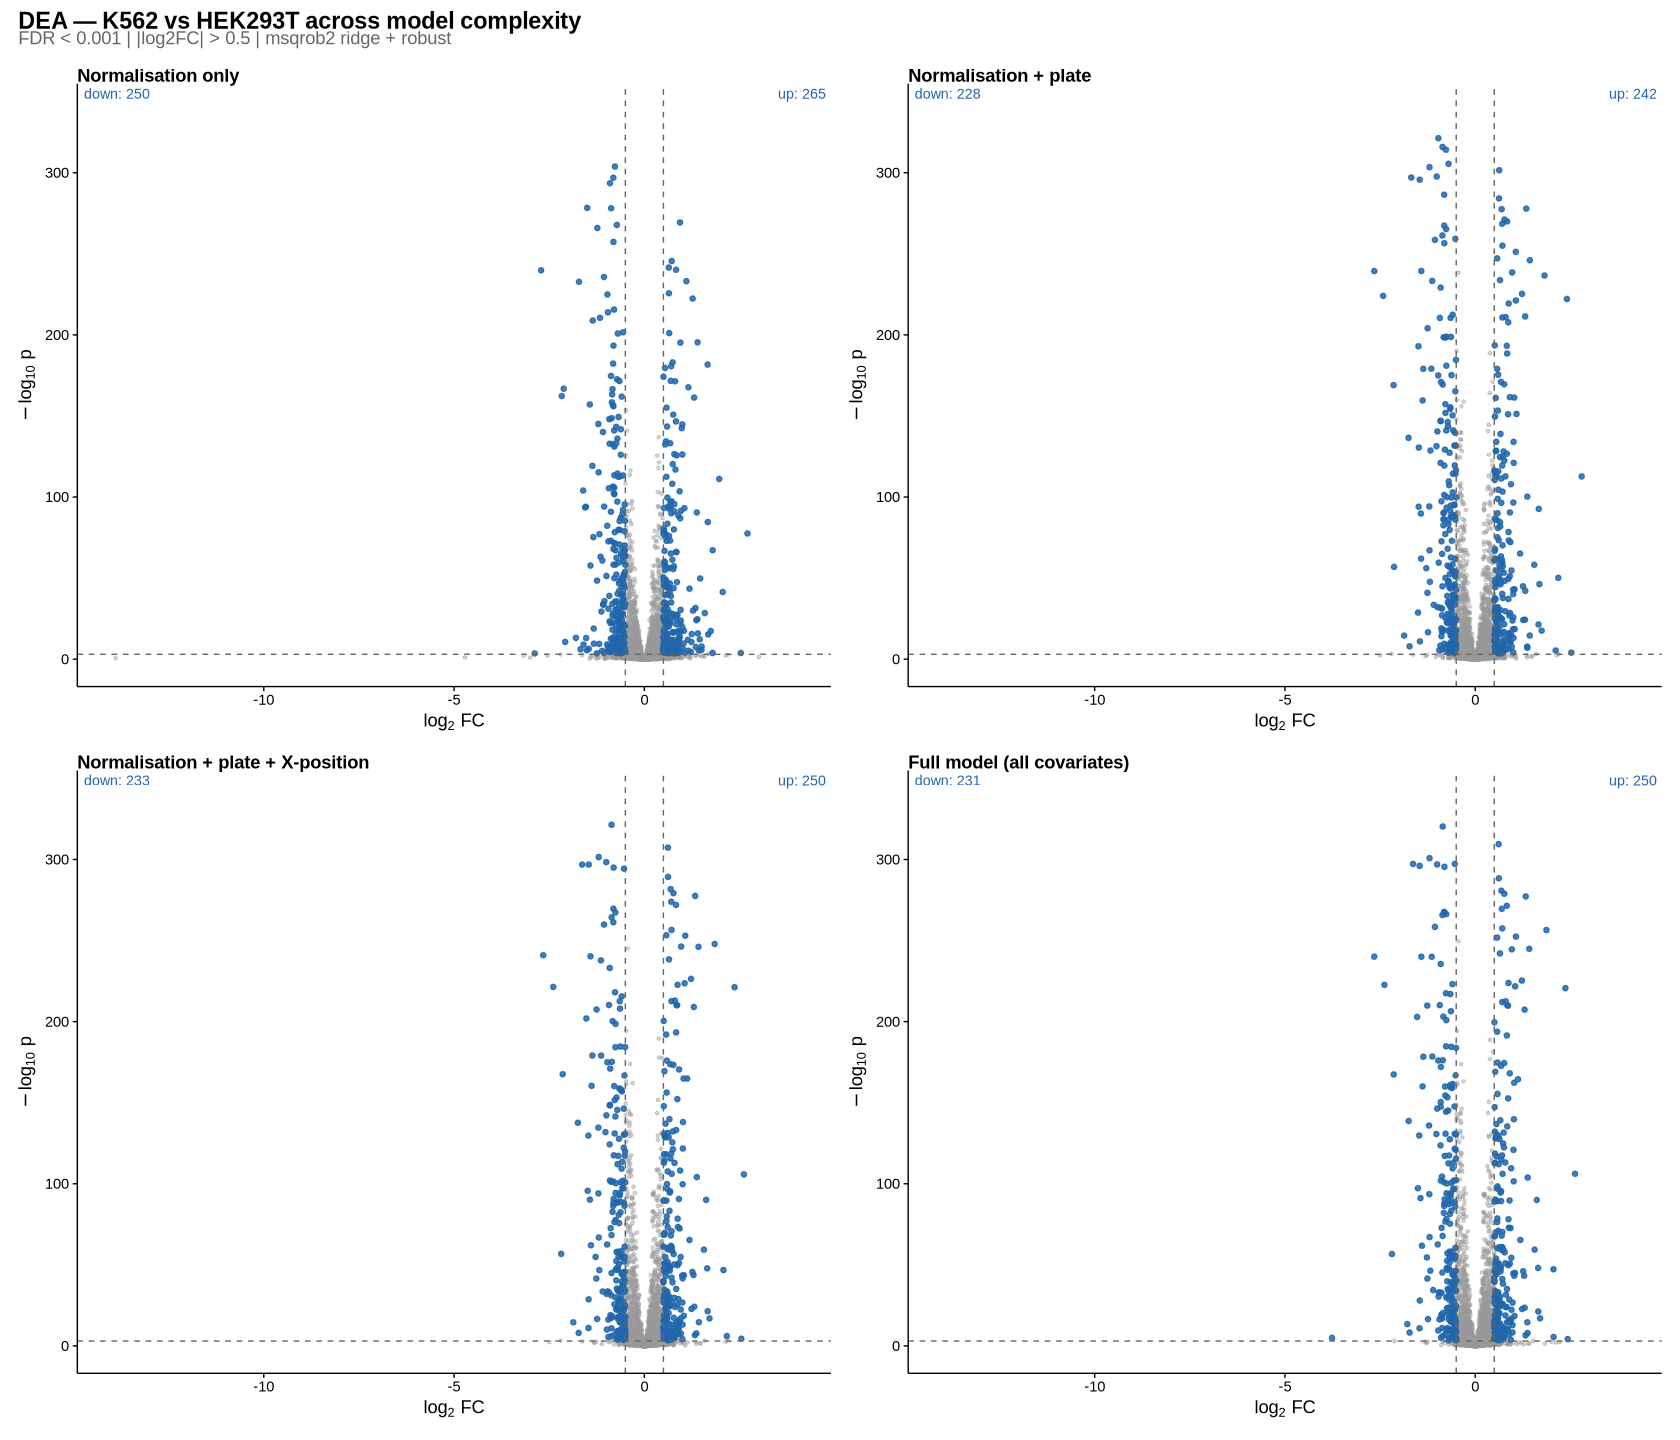

In [16]:
plot_volcano_grid(
    model_configs = model_configs,
    save_dir      = FIG_OUT,
    filename      = "volcano_grid",
    show          = TRUE
)

### 7.5 UpSet plot — model overlap

Shows how the significant protein sets overlap across the four integrated models.

Significant proteins per model:
                Normalisation only              Normalisation + plate 
                               529                                494 
Normalisation + plate + X-position        Full model (all covariates) 
                               510                                508 


Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue to the authors.”


Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue to the authors.”
Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue to the authors.”


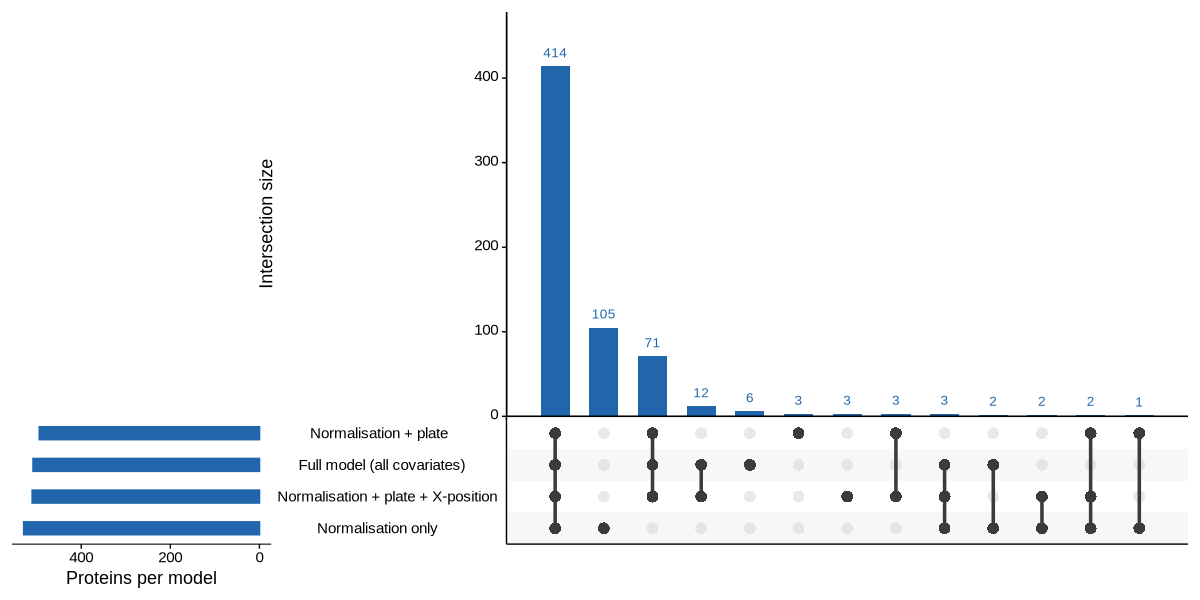

In [17]:
plot_upset_sig(
    model_configs = model_configs,
    save_dir      = FIG_OUT,
    filename      = "upset_sig",
    show          = TRUE
)

### 7.6 logFC and SE comparison across models

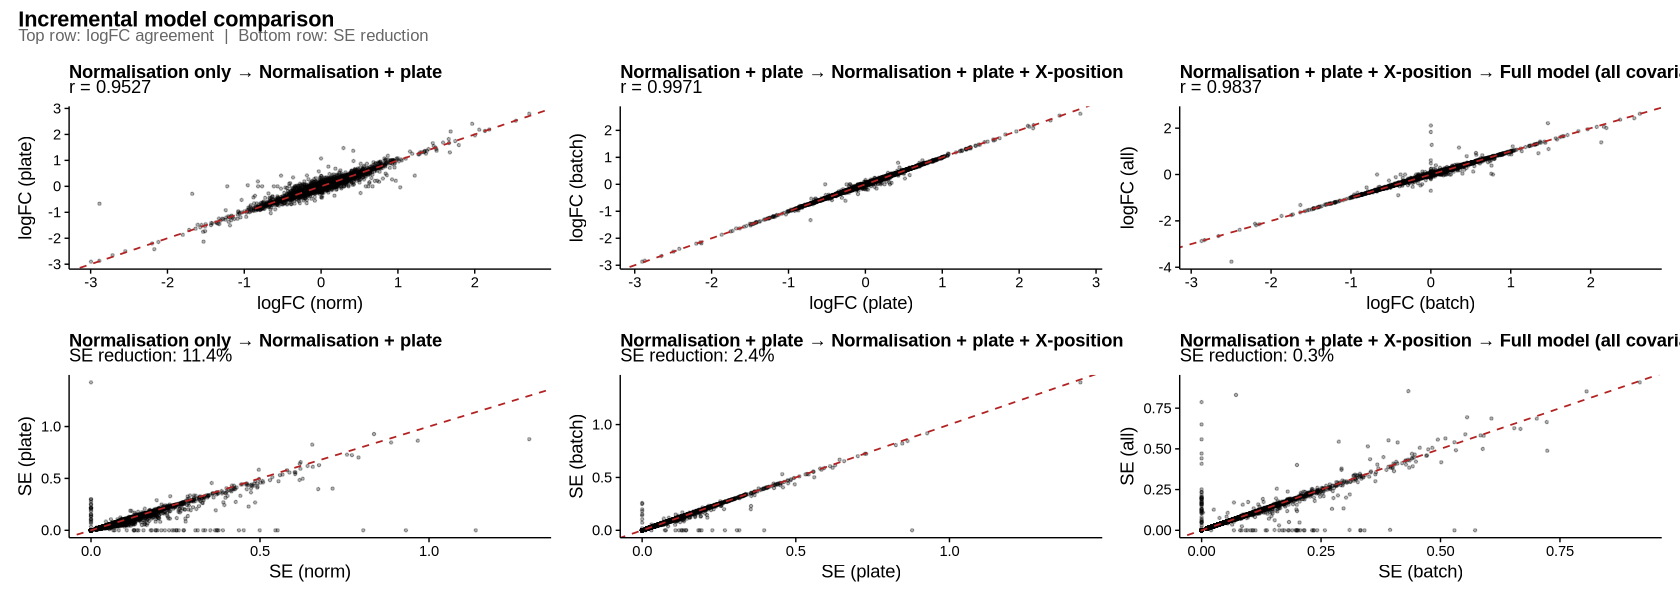

In [18]:
plot_model_comparison_grid(
    model_configs = model_configs,
    save_dir      = FIG_OUT,
    filename      = "model_comparison_grid",
    show          = TRUE
)

## 8. Batch-corrected sanity checks

`limma::removeBatchEffect` is used only for visualisation: it removes the plate effect and the technical covariates while keeping the cell-type contrast, so the corrected intensities can be inspected directly. It is not used for the statistical testing above.

In [19]:
batch_corrected <- removeBatchEffect(
    assay(qf[["proteins_medianPolish"]]),
    batch      = colData(qf)$plate_id,
    covariates = cbind(
        colData(qf)$medianIntensityProtein,
        colData(qf)$n_proteins,
        colData(qf)$injection_order,
        colData(qf)$comment.X.position.
    ),
    design = model.matrix(~ source.name, data = as.data.frame(colData(qf)))
)
assay(qf[["proteins_medianPolish"]], "batch_corrected") <- batch_corrected

cat(sprintf("NA before correction : %.1f%%\n",
            100 * mean(is.na(assay(qf[["proteins_medianPolish"]], 1)))))
cat(sprintf("NA after correction  : %.1f%%\n",
            100 * mean(is.na(batch_corrected))))

Warning message:
“Partial NA coefficients for 5095 probe(s)”


NA before correction : 70.6%
NA after correction  : 70.6%


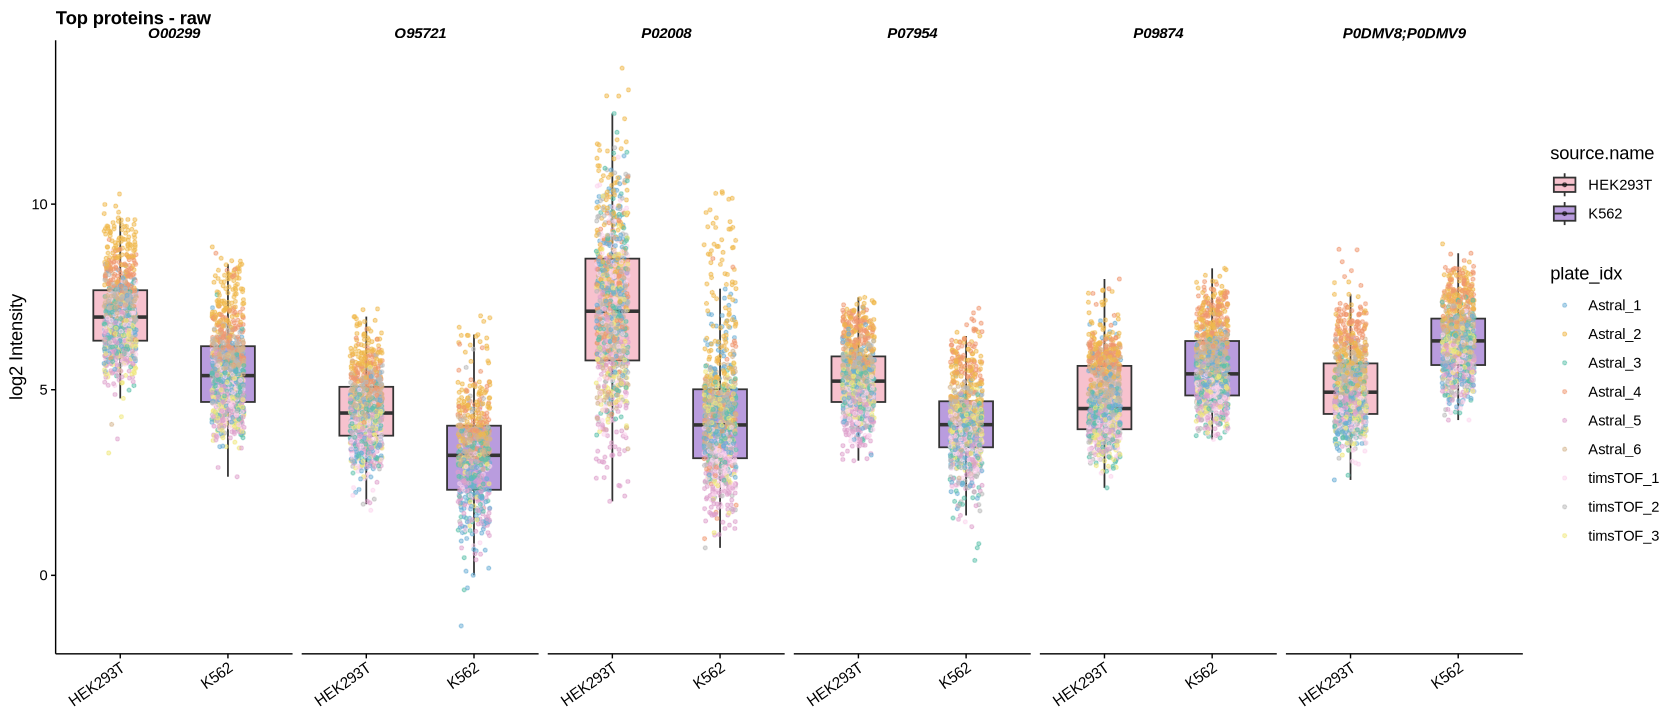

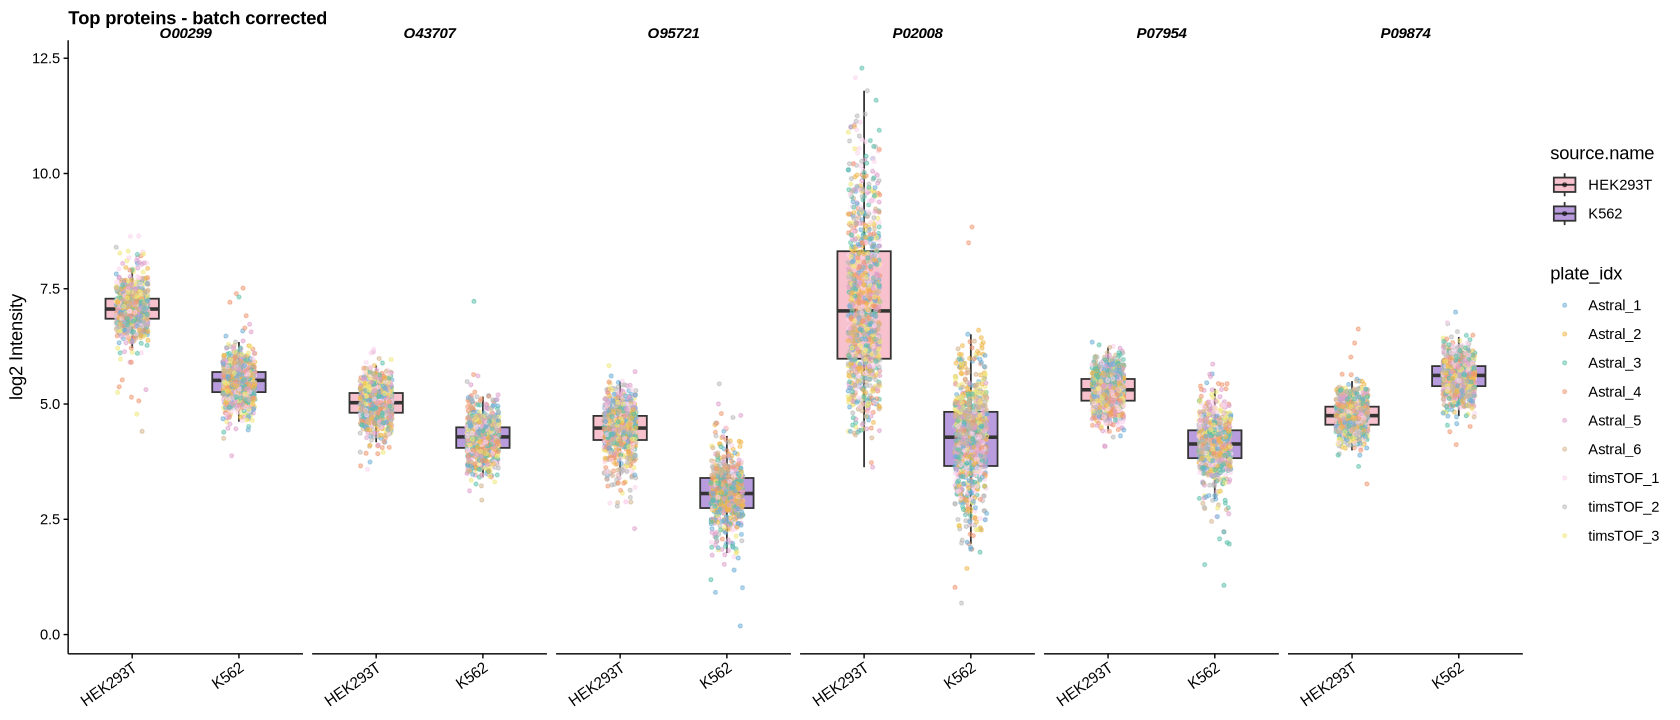

In [20]:
plot_top_proteins(res_norm, qf,
    experiment_name = "proteins_medianPolish",
    assay_name      = 1,
    title           = "Top proteins - raw",
    save_dir        = FIG_OUT,
    filename        = "top_proteins_norm_raw",
    share_y         = TRUE,
    show            = TRUE
)

plot_top_proteins(res_all, qf,
    experiment_name = "proteins_medianPolish",
    assay_name      = "batch_corrected",
    title           = "Top proteins - batch corrected",
    save_dir        = FIG_OUT,
    filename        = "top_proteins_all_corrected",
    share_y         = TRUE,
    show            = TRUE
)

### 8.1 PCA on differentially regulated proteins

If the DE list is meaningful, cells should separate by cell type along PC1 while plates stay well mixed. A matched set of non-significant proteins is shown as a negative control.

In [21]:
plot_pca_proteins <- function(
    qf,
    proteins,
    experiment_name = "proteins_medianPolish",
    assay_name      = "batch_corrected",
    min_obs_pct     = 0.25,
    colour_vars     = c(COL_CELL_TYPE, COL_PLATE),
    title           = "PCA",
    save_dir        = NULL,
    filename        = "pca_proteins",
    width           = 12,
    height          = 5,
    show            = TRUE
) {
    mat <- assay(qf[[experiment_name]], assay_name)[proteins, , drop = FALSE]

    # drop sparse proteins, then impute remaining NAs with the row mean
    keep    <- rowSums(!is.na(mat)) >= min_obs_pct * ncol(mat)
    mat     <- mat[keep, ]
    mat_imp <- t(apply(mat, 1, function(x) { x[is.na(x)] <- mean(x, na.rm = TRUE); x }))
    cat(sprintf("Proteins into PCA: %d / %d\n", nrow(mat_imp), length(proteins)))

    pca      <- prcomp(t(mat_imp), scale. = TRUE, center = TRUE)
    var_expl <- summary(pca)$importance[2, 1:2] * 100

    df_pca <- data.frame(PC1 = pca$x[, 1], PC2 = pca$x[, 2]) %>%
        rownames_to_column("cell") %>%
        left_join(as.data.frame(colData(qf)) %>% rownames_to_column("cell"), by = "cell")

    panels <- lapply(colour_vars, function(cv) {
        colour_scale <- if (cv == COL_CELL_TYPE) {
            scale_colour_manual(values = CONDITION_COLORS, name = cv)
        } else if (cv == COL_PLATE) {
            scale_colour_manual(values = LAB_COLORS, name = cv)
        } else {
            scale_colour_brewer(palette = "Set2", name = cv)
        }
        ggplot(df_pca, aes(x = PC1, y = PC2, colour = .data[[cv]])) +
            geom_point(size = 1.5, alpha = 0.7) +
            colour_scale +
            labs(title = title,
                 subtitle = sprintf("%d proteins | %s", nrow(mat_imp), cv),
                 x = sprintf("PC1 (%.1f%%)", var_expl[1]),
                 y = sprintf("PC2 (%.1f%%)", var_expl[2])) +
            theme(plot.title = element_text(face = "bold"))
    })

    fig <- Reduce(`|`, panels)
    if (!is.null(save_dir)) save_figure(fig, file.path(save_dir, filename), width = width, height = height)
    if (show) { options(repr.plot.width = width, repr.plot.height = height); print(fig) }
    invisible(fig)
}

Significant proteins: 508
Proteins into PCA: 356 / 508
Proteins into PCA: 356 / 508


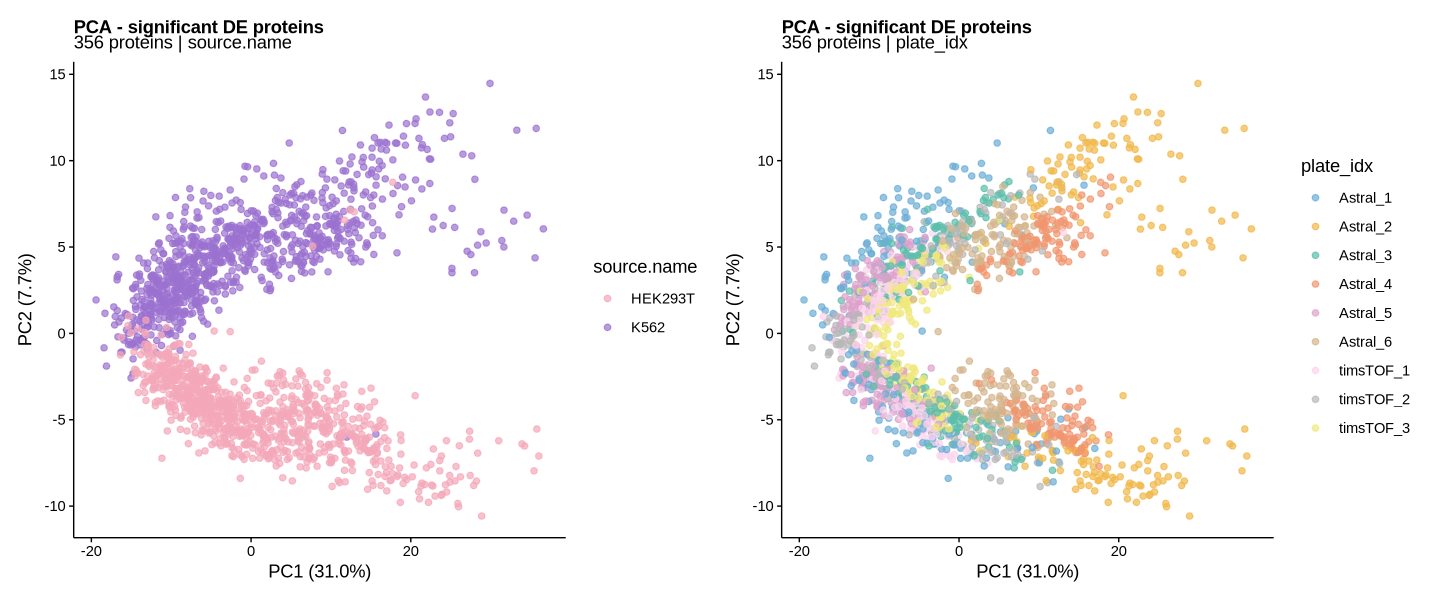

Non-significant proteins sampled: 508
Proteins into PCA: 159 / 508


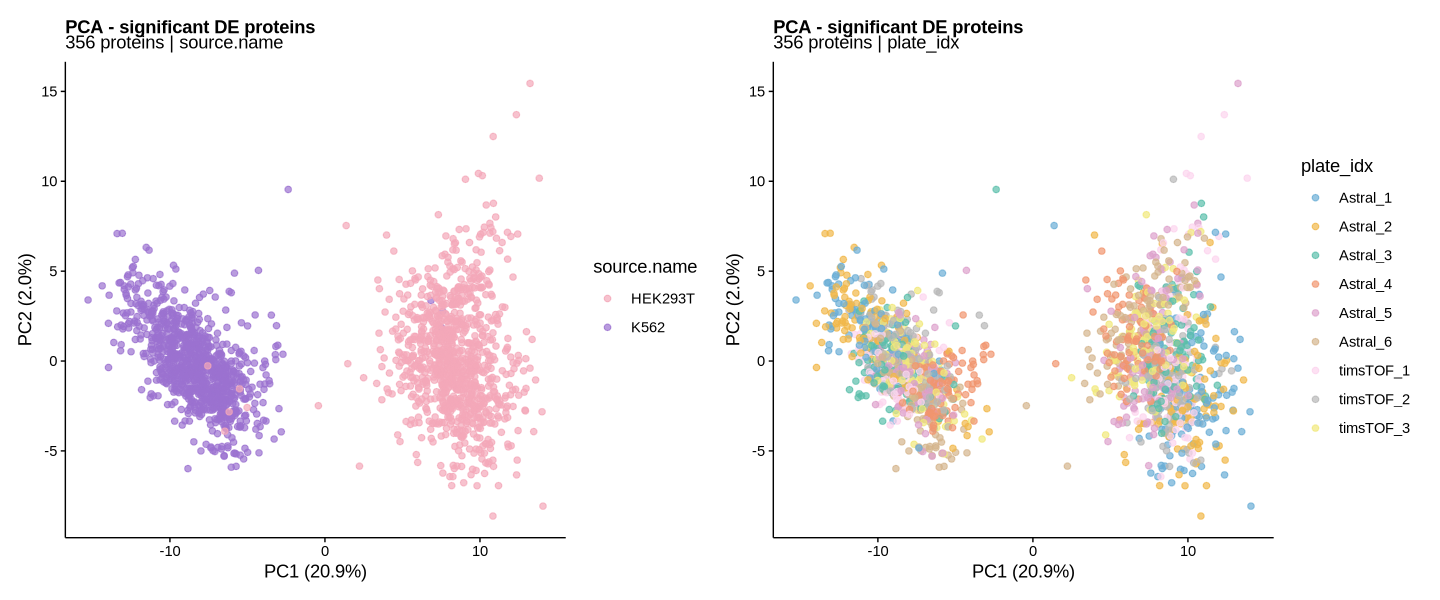

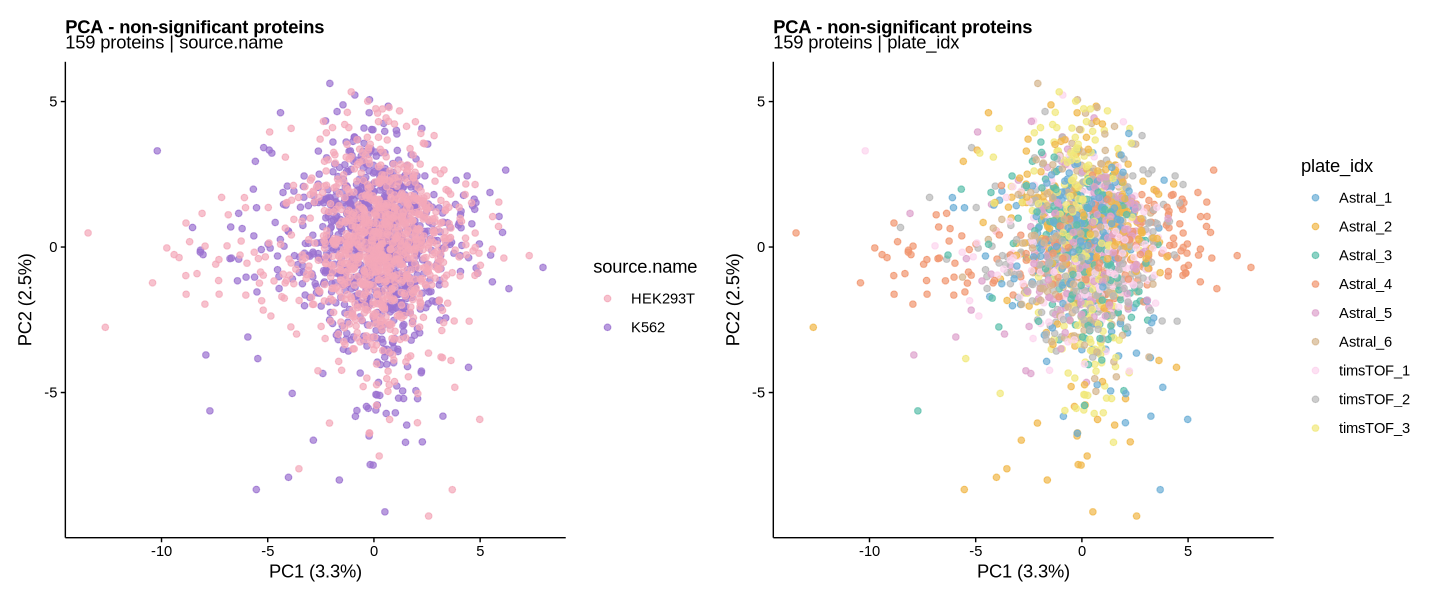

In [22]:
# Significant proteins from the full model
sig_proteins <- res_all %>%
    filter(!is.na(adjPval), adjPval < FDR_THRESHOLD, abs(logFC) > FC_THRESHOLD) %>%
    pull(protein)
cat(sprintf("Significant proteins: %d\n", length(sig_proteins)))

plot_pca_proteins(qf, sig_proteins, assay_name = 1,
    title = "PCA - significant DE proteins",
    save_dir = FIG_OUT, filename = "pca_sig_proteins_uncorrected", show = TRUE)
plot_pca_proteins(qf, sig_proteins, assay_name = "batch_corrected",
    title = "PCA - significant DE proteins",
    save_dir = FIG_OUT, filename = "pca_sig_proteins_corrected", show = TRUE)

# Matched non-significant control set
ns_proteins <- res_all %>%
    filter(!is.na(adjPval), adjPval >= FDR_THRESHOLD, abs(logFC) < FC_THRESHOLD) %>%
    slice_sample(n = length(sig_proteins)) %>%
    pull(protein)
cat(sprintf("Non-significant proteins sampled: %d\n", length(ns_proteins)))

plot_pca_proteins(qf, ns_proteins, assay_name = "batch_corrected",
    title = "PCA - non-significant proteins",
    save_dir = FIG_OUT, filename = "pca_ns_proteins_corrected", show = TRUE)

## 9. Per-plate analysis

Each plate is fitted independently, simulating a single-lab experiment. There is no `plate_id` term (no between-plate correction is needed within a single plate); `n_proteins` and `medianIntensityProtein` act as within-plate normalisation. The date random effect is dropped for plates with a single acquisition day.

The per-plate models are restricted to the **same protein set as the integrated analysis** (`feature_set` below), so the two are directly comparable.

In [23]:
# ---- Parameters -------------------------------------------------------------
formula_default <- ~ 0 + source.name +
    medianIntensityProtein + n_proteins +
    comment.X.position. + injection_order

# ---- Helper: drop the date random effect if it has < 2 levels ---------------
drop_date_re <- function(formula) {
    as.formula(sub("\\+ \\(1 \\| comment\\.Gradient\\.time\\._date\\)", "",
                   deparse(formula)))
}

# ---- Helper: fit one plate --------------------------------------------------
fit_plate <- function(plate, qf) {
    cat(sprintf("-- %s --\n", plate)); flush.console()

    qf_p    <- qf[, colData(qf)[[COL_PLATE]] == plate]
    n_cells <- ncol(qf_p[["precursors_log"]])

    qf_p <- tryCatch(
        aggregateFeatures(qf_p, i = "precursors_log", fcol = PG_COL,
                          name = "proteins_medianPolish_lab",
                          fun  = MsCoreUtils::medianPolish, na.rm = TRUE),
        error = function(e) { cat(sprintf("  aggregation failed: %s\n", e$message)); NULL }
    )
    if (is.null(qf_p)) return(NULL)

    qf_p <- tryCatch(
        msqrob(qf_p, i = "proteins_medianPolish_lab", formula = formula_default,
               modelColumnName = "msqrob_lab", ridge = TRUE, robust = TRUE),
        error = function(e) { cat(sprintf("  model failed: %s\n", e$message)); NULL }
    )
    if (is.null(qf_p)) return(NULL)

    L <- makeContrast(CONTRAST_STR, parameterNames = CONTRAST_PARAMS)

    qf_p <- tryCatch(
        hypothesisTest(qf_p, i = "proteins_medianPolish_lab", contrast = L,
                       modelColumn = "msqrob_lab",
                       resultsColumnNamePrefix = "lab_dea_", adjust.method = "BH"),
        error = function(e) { cat(sprintf("  hypothesis test failed: %s\n", e$message)); NULL }
    )
    if (is.null(qf_p)) return(NULL)

    result_col <- paste0("lab_dea_", gsub(" = 0", "", CONTRAST_STR))
    res <- tryCatch(
        rowData(qf_p[["proteins_medianPolish_lab"]])[[result_col]] %>%
            as.data.frame() %>%
            rownames_to_column("protein") %>%
            mutate(plate = plate) %>%
            arrange(pval),
        error = function(e) NULL
    )
    if (is.null(res)) return(NULL)

    n_sig <- sum(res$adjPval < FDR_THRESHOLD & abs(res$logFC) > FC_THRESHOLD, na.rm = TRUE)
    cat(sprintf("  significant: %d / %d\n\n", n_sig, nrow(res)))

    write.csv(res, file.path(PER_PLATE_DIR, sprintf("dea_%s.csv", gsub("[/ ]", "_", plate))),
              row.names = FALSE)
    res
}

In [24]:
plates <- levels(colData(qf)[[COL_PLATE]])
cat(sprintf("Running per-plate msqrob for %d plates...\n\n",
            length(plates)))

results_per_plate <- setNames(
    lapply(plates, fit_plate, qf = qf),
    plates
)
results_per_plate <- Filter(Negate(is.null), results_per_plate)
cat(sprintf("Successfully fitted: %d / %d plates\n", length(results_per_plate), length(plates)))

write.csv(bind_rows(results_per_plate),
          file.path(PER_PLATE_DIR, "combined.csv"), row.names = FALSE)
saveRDS(results_per_plate, file.path(PER_PLATE_DIR, "results_per_plate.rds"))

Running per-plate msqrob for 9 plates...

-- Astral_1 --


Your quantitative and row data contain missing values. Please read the
relevant section(s) in the aggregateFeatures manual page regarding the
effects of missing values on data aggregation.

Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warni

  significant: 456 / 6628

-- Astral_2 --


Your quantitative and row data contain missing values. Please read the
relevant section(s) in the aggregateFeatures manual page regarding the
effects of missing values on data aggregation.

Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warni

  significant: 567 / 6628

-- Astral_3 --


Your quantitative and row data contain missing values. Please read the
relevant section(s) in the aggregateFeatures manual page regarding the
effects of missing values on data aggregation.

Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warni

... (9 outputs left out)

Your quantitative and row data contain missing values. Please read the
relevant section(s) in the aggregateFeatures manual page regarding the
effects of missing values on data aggregation.

Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warni

  significant: 380 / 6628

-- timsTOF_3 --


Your quantitative and row data contain missing values. Please read the
relevant section(s) in the aggregateFeatures manual page regarding the
effects of missing values on data aggregation.

Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warni

  significant: 257 / 6628

Successfully fitted: 9 / 9 plates


## 10. Integrated vs per-plate overlap

The integrated full model (`res_all`) and the per-plate results are compared on the same protein set. Both are reloaded from `RESULTS_DIR` so this section can be run on its own.

In [25]:
res_all           <- readRDS(file.path(DEA_RDS_DIR, "res_all.rds"))
results_per_plate <- readRDS(file.path(PER_PLATE_DIR, "results_per_plate.rds"))
cat(sprintf("Integrated proteins: %d | per-plate results: %d plates\n",
            nrow(res_all), length(results_per_plate)))

Integrated proteins: 6628 | per-plate results: 9 plates


In [26]:
# Reload remaining integrated model results (allows sections 7.4–7.6 to run standalone)
for (nm in c("norm", "plate", "batch")) {
    assign(paste0("res_", nm),
           readRDS(file.path(DEA_RDS_DIR, sprintf("res_%s.rds", nm))))
}
cat("Loaded: res_norm, res_plate, res_batch\n")

Loaded: res_norm, res_plate, res_batch


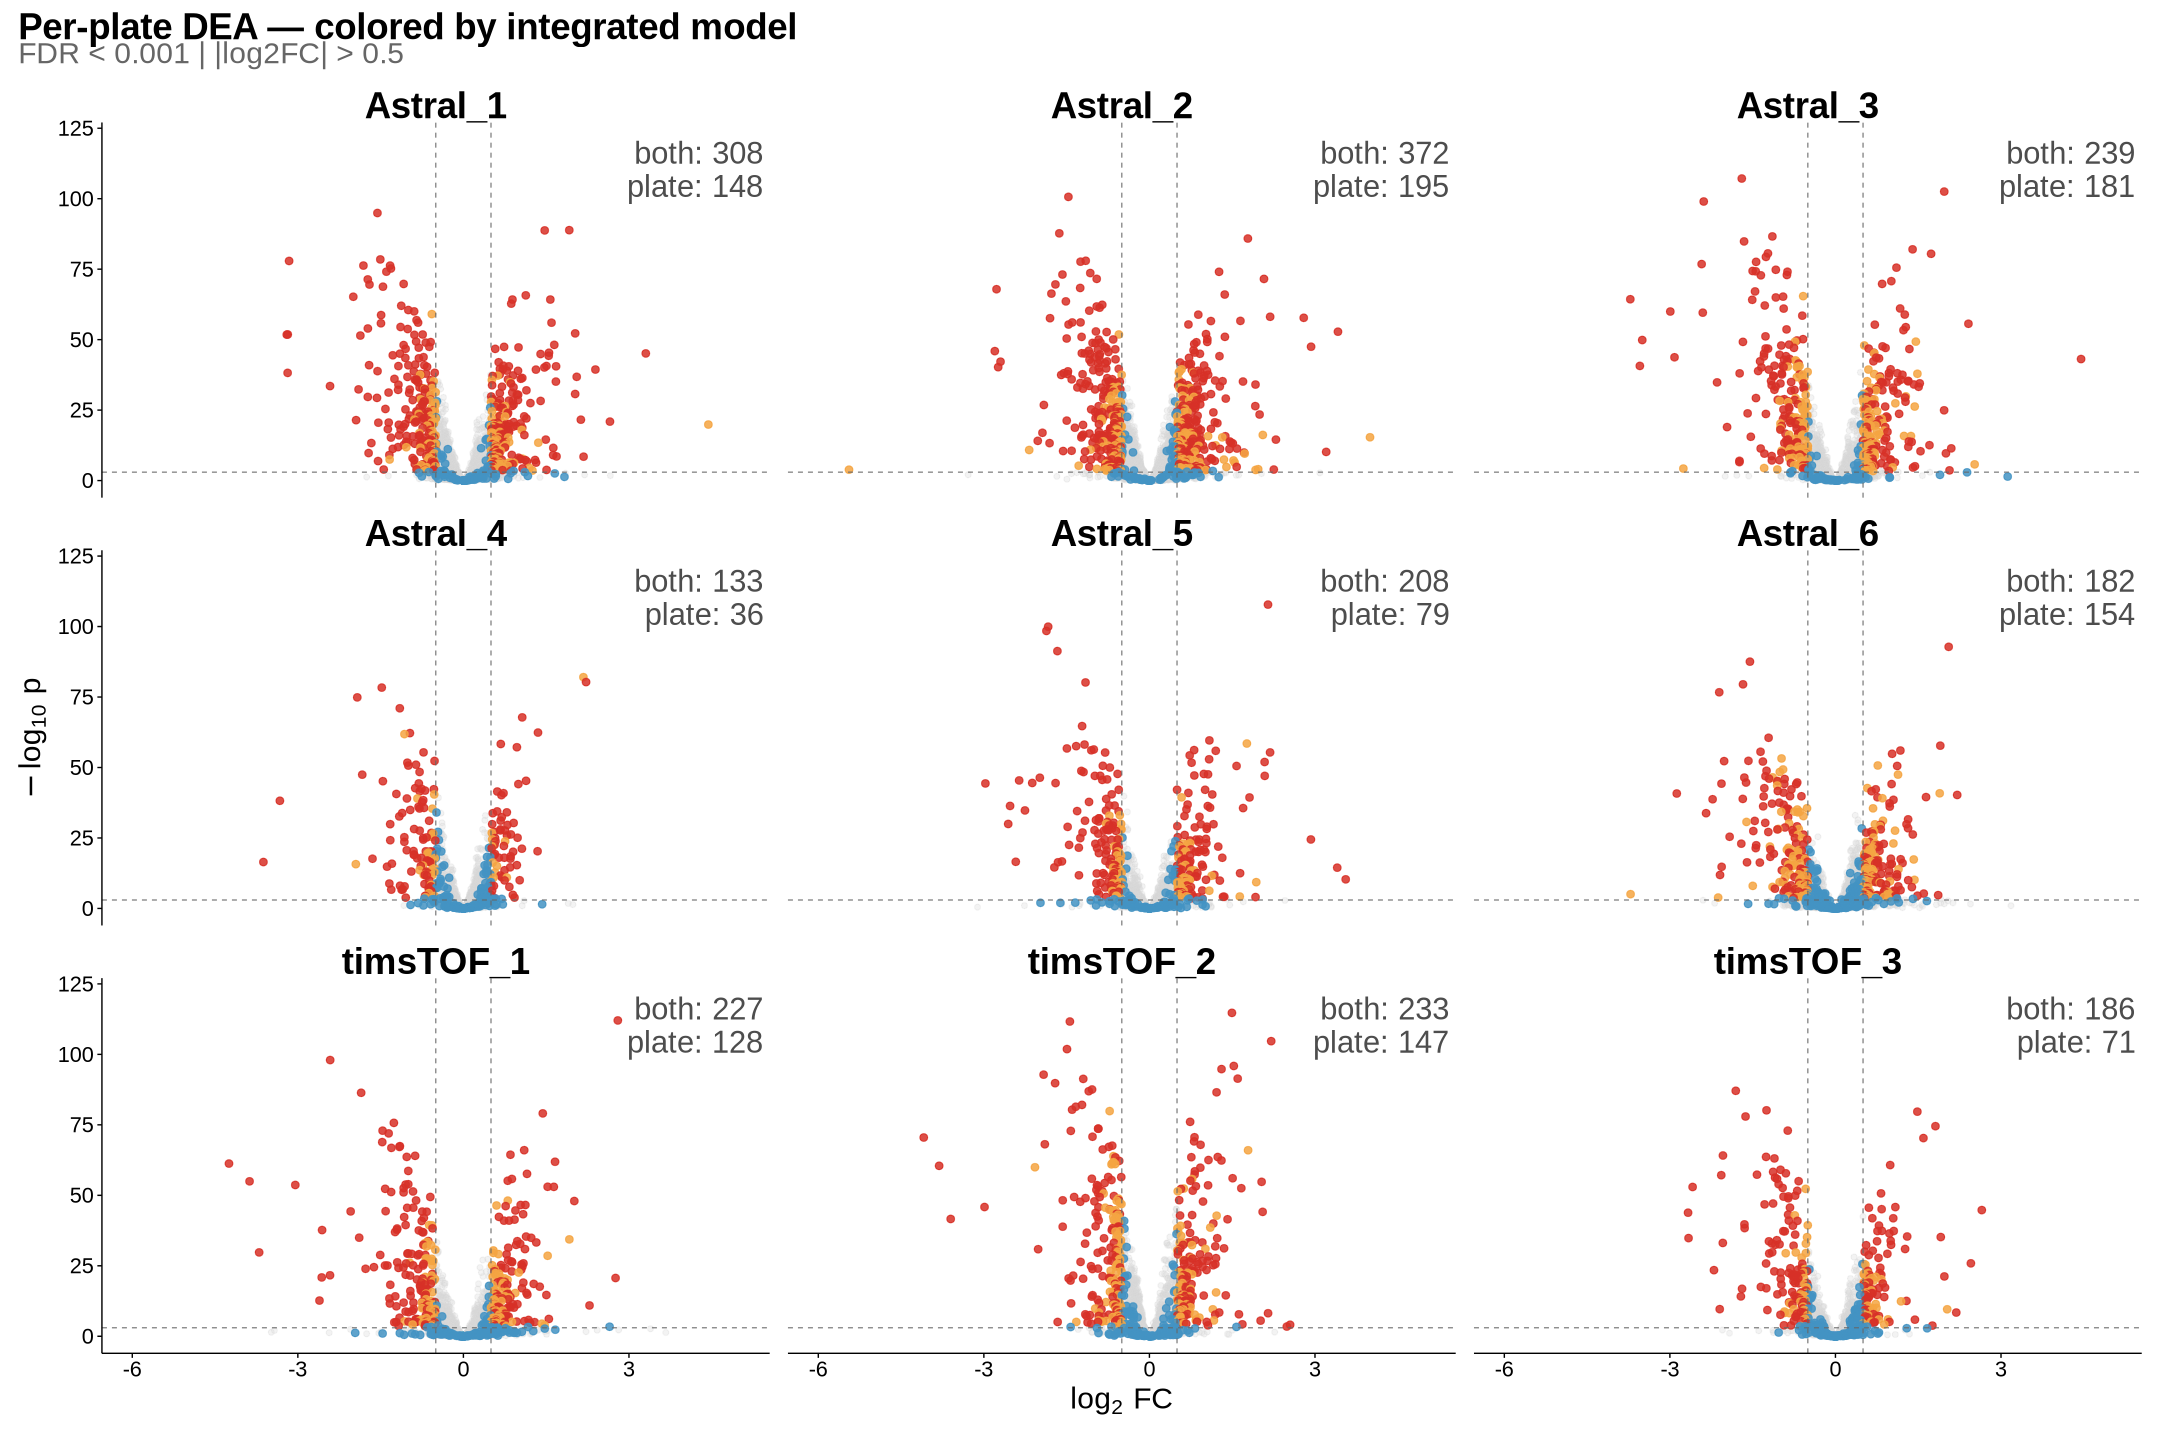

In [27]:
plot_volcano_grid_per_plate(
    results_per_plate = results_per_plate,
    res_integrated    = res_all,
    fdr_threshold     = FDR_THRESHOLD,
    fc_threshold      = FC_THRESHOLD,
    save_dir          = FIG_OUT,
    filename          = "volcano_grid_per_plate",
    show              = TRUE
)


Upregulated proteins per model:
Integrated   Astral_1   Astral_2   Astral_3   Astral_4   Astral_5   Astral_6 
       256        226        279        212         66        140        160 
 timsTOF_1  timsTOF_2  timsTOF_3 
       174        177        110 

Downregulated proteins per model:
Integrated   Astral_1   Astral_2   Astral_3   Astral_4   Astral_5   Astral_6 
       252        230        288        208        103        147        176 
 timsTOF_1  timsTOF_2  timsTOF_3 
       181        203        147 

Differentiallyregulated proteins per model:
Integrated   Astral_1   Astral_2   Astral_3   Astral_4   Astral_5   Astral_6 
       508        456        567        420        169        287        336 
 timsTOF_1  timsTOF_2  timsTOF_3 
       355        380        257 


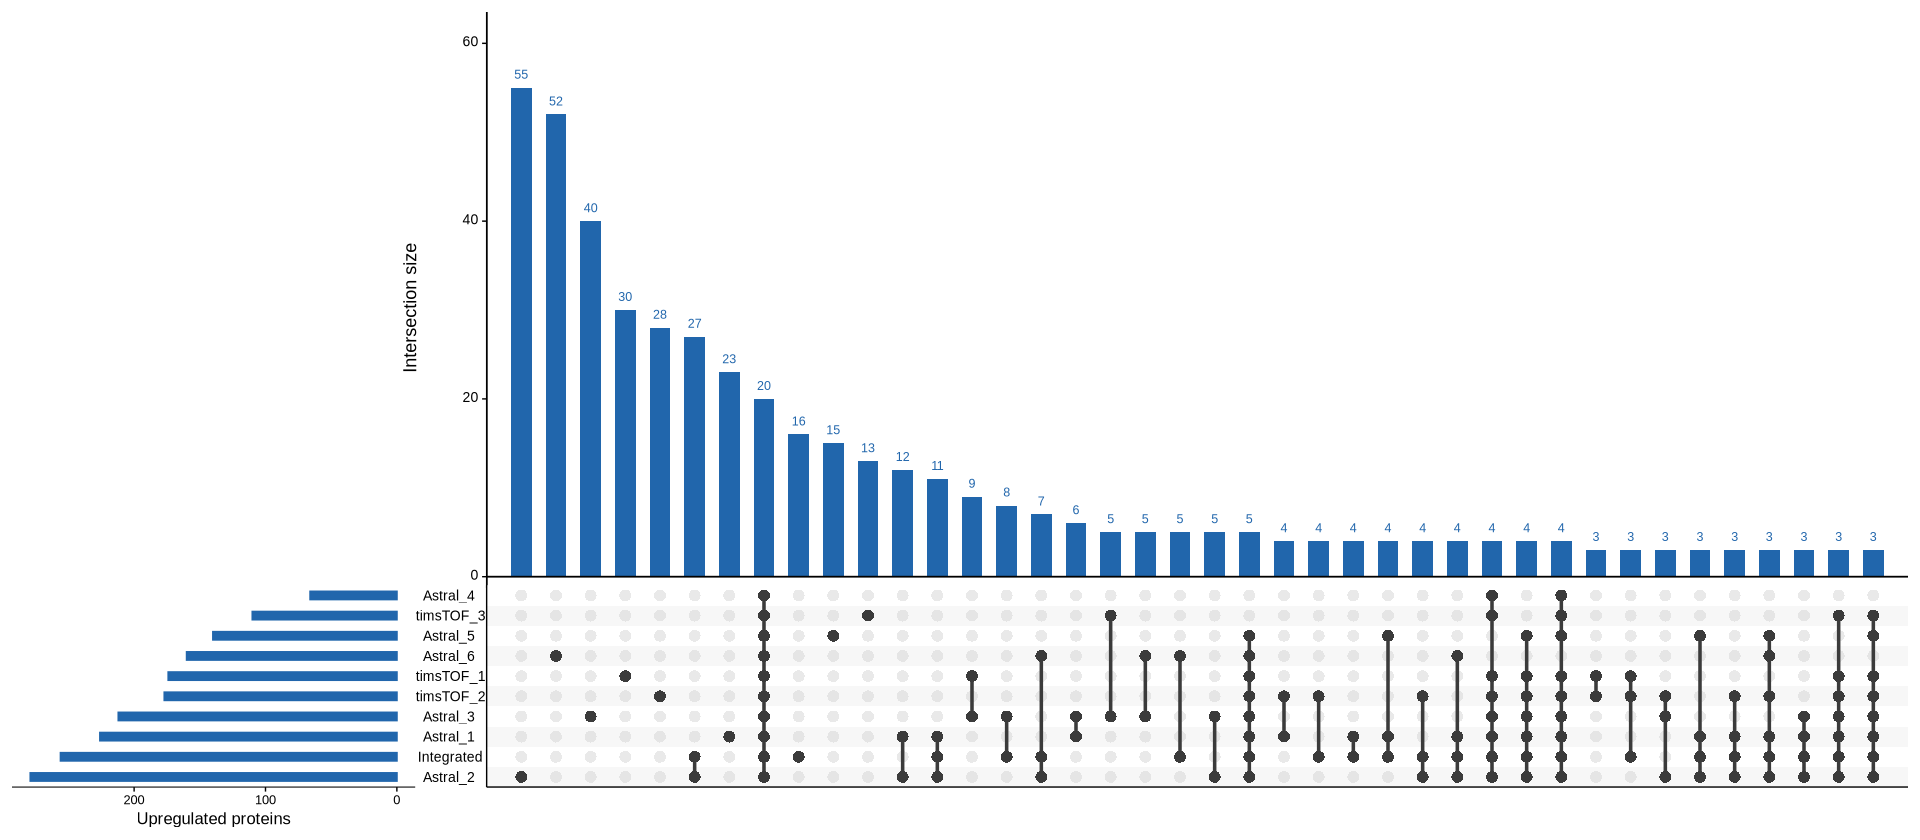

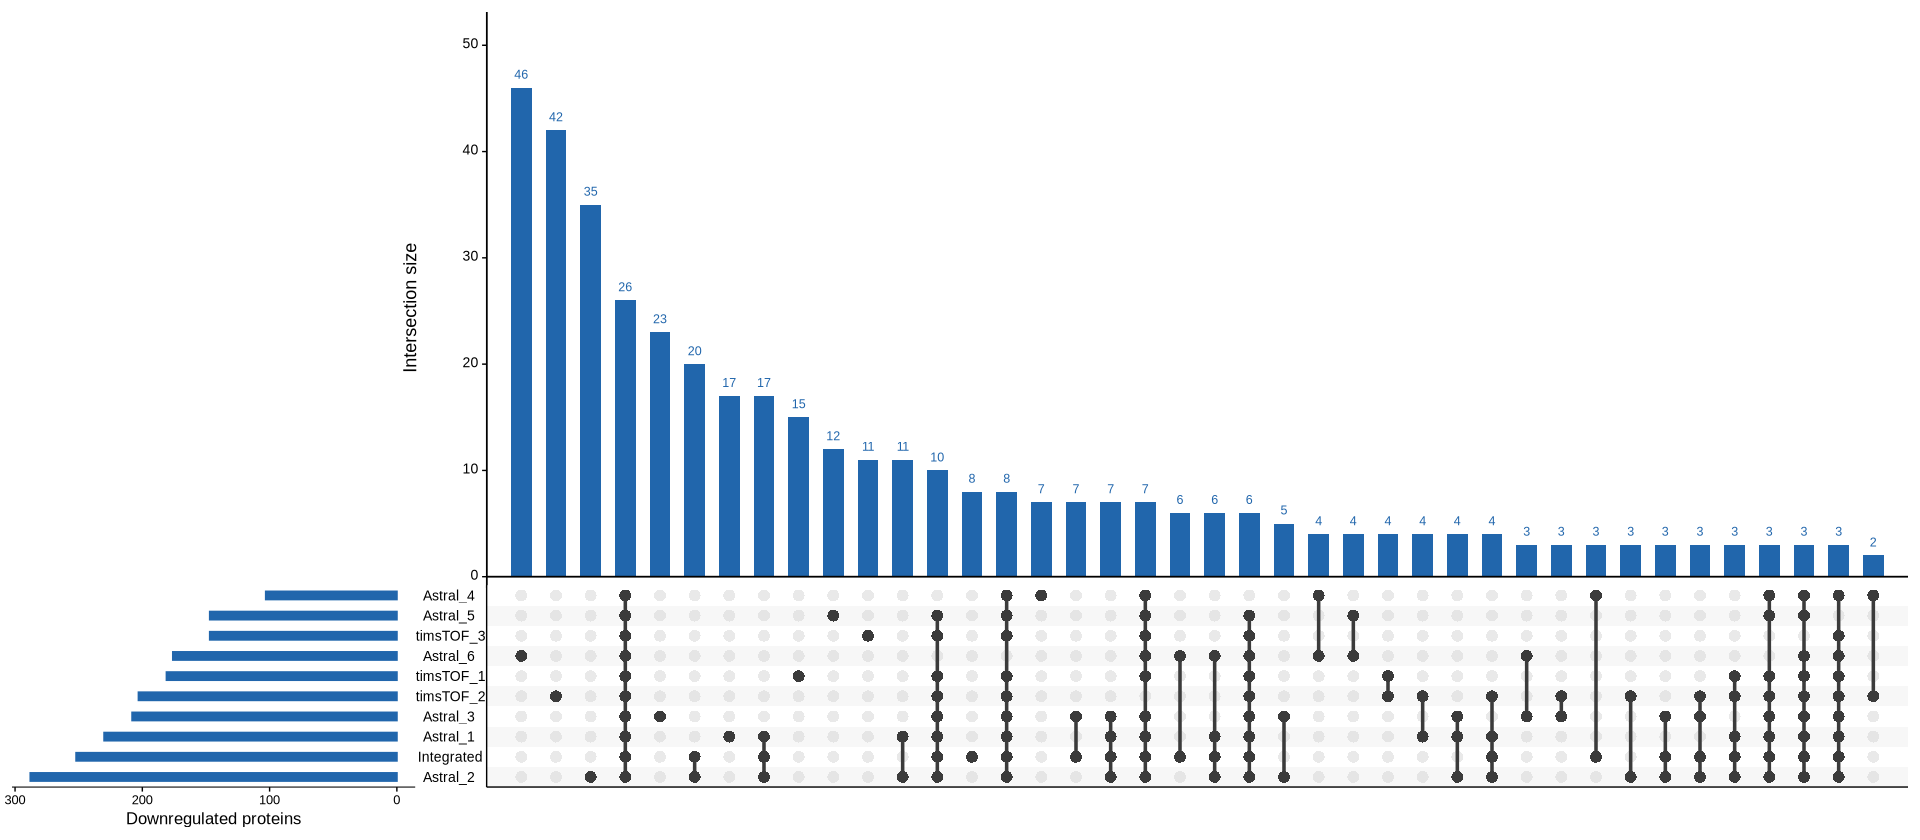

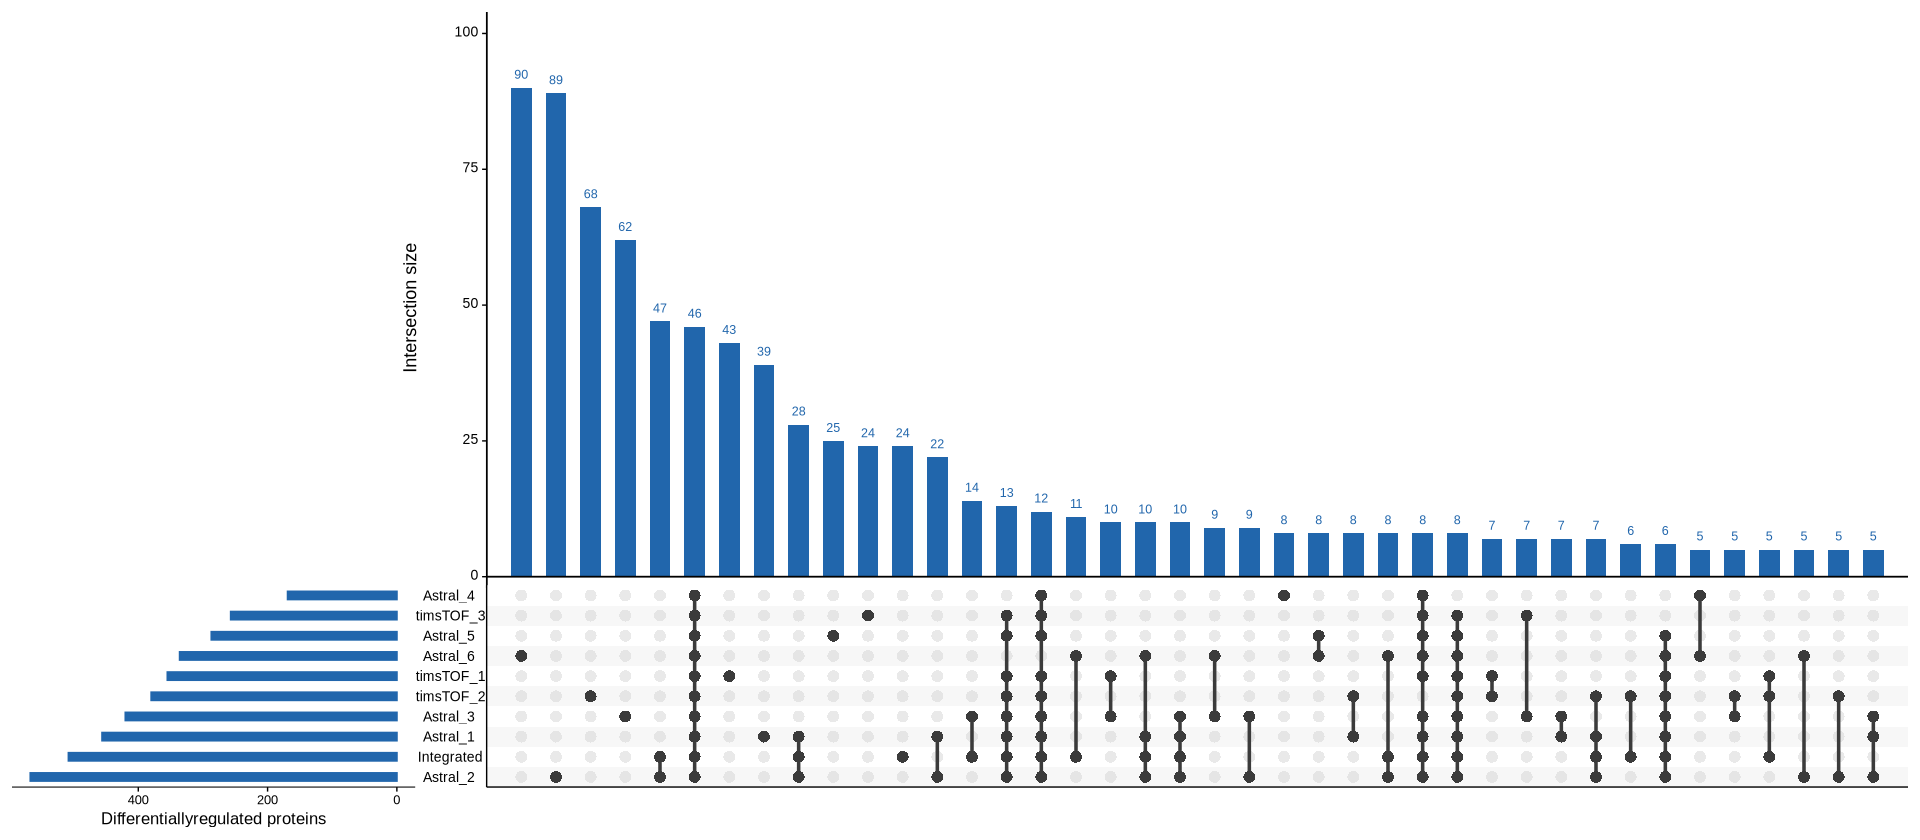

In [28]:
plot_upset_per_plate(
    results_per_plate = results_per_plate,
    res_integrated    = res_all,
    fdr_threshold     = FDR_THRESHOLD,
    fc_threshold      = FC_THRESHOLD,
    save_dir          = FIG_OUT,
    filename          = "upset_per_plate",
    show              = TRUE
)

logFC correlation computed on 1202 proteins (union of significant)


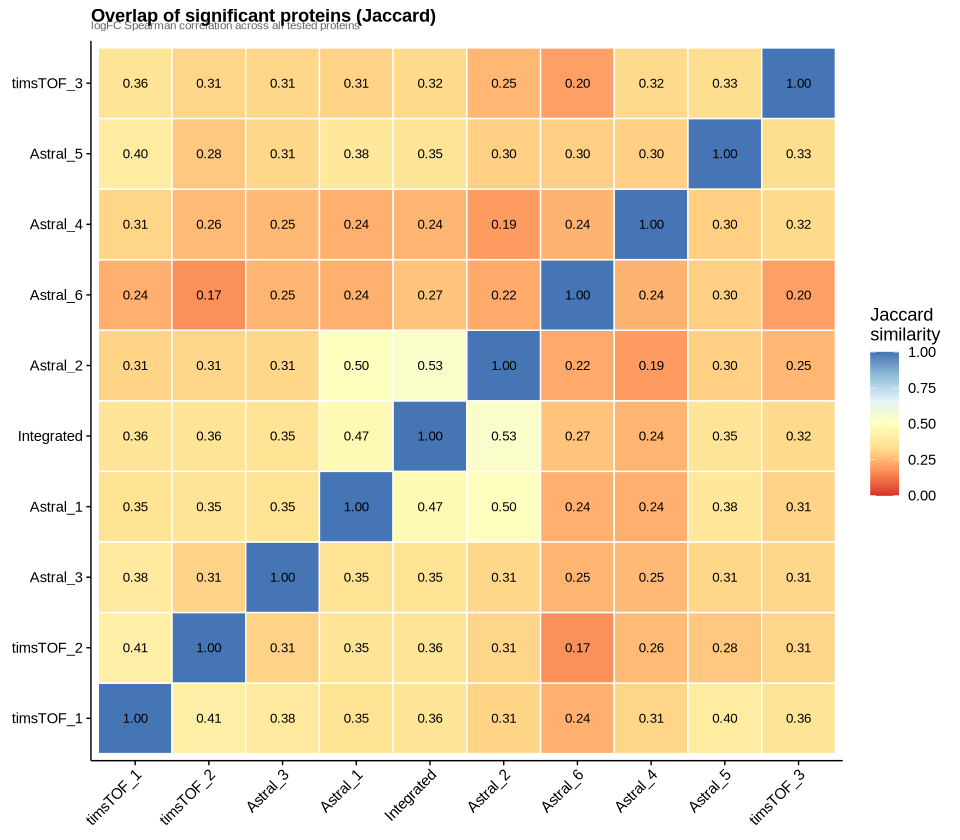

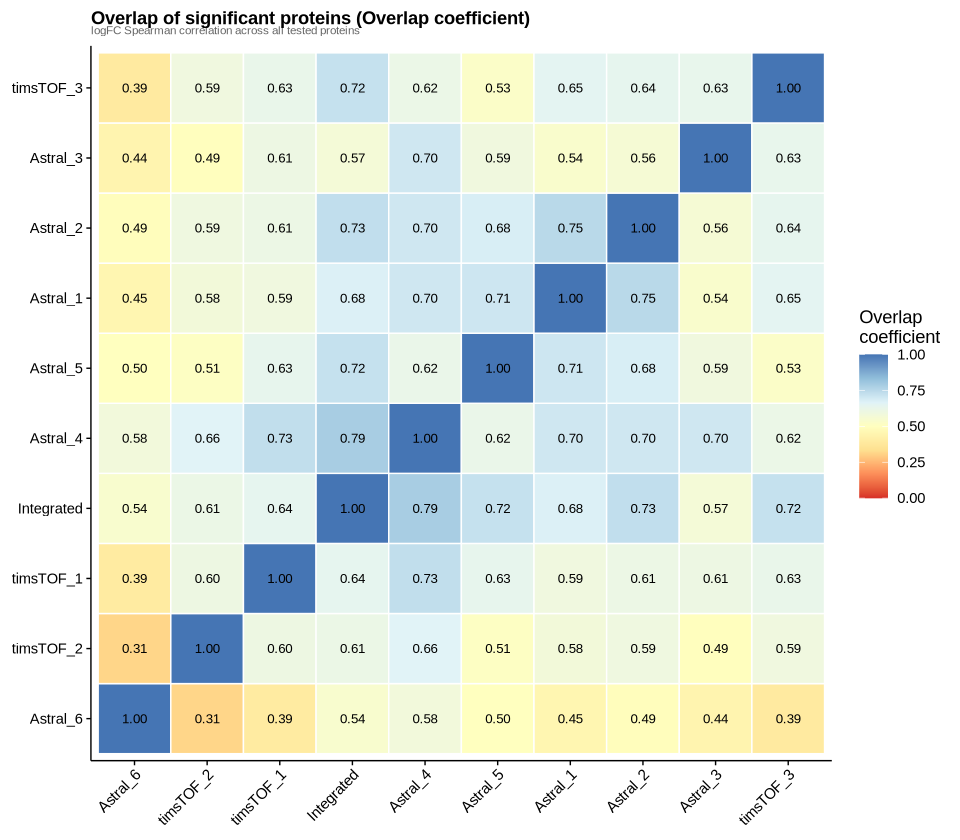

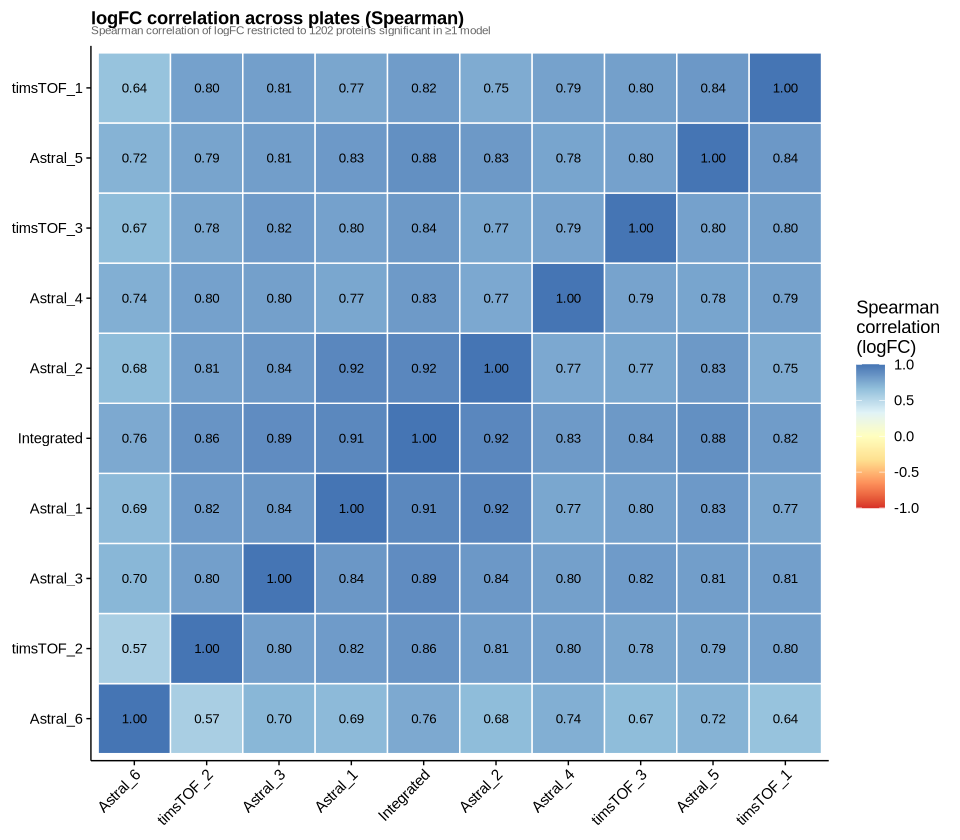

In [29]:
for (m in c("jaccard", "overlap", "logfc_cor")) {
    plot_overlap_heatmap(
        results_per_plate, res_all,
        metric   = m,
        save_dir = FIG_OUT,
        filename = sprintf("overlap_heatmap_%s.png", m)
    )
}

### 10.1 Per-plate logFC distributions

A quick diagnostic: each plate's logFC distribution should be centred near zero if normalisation worked.

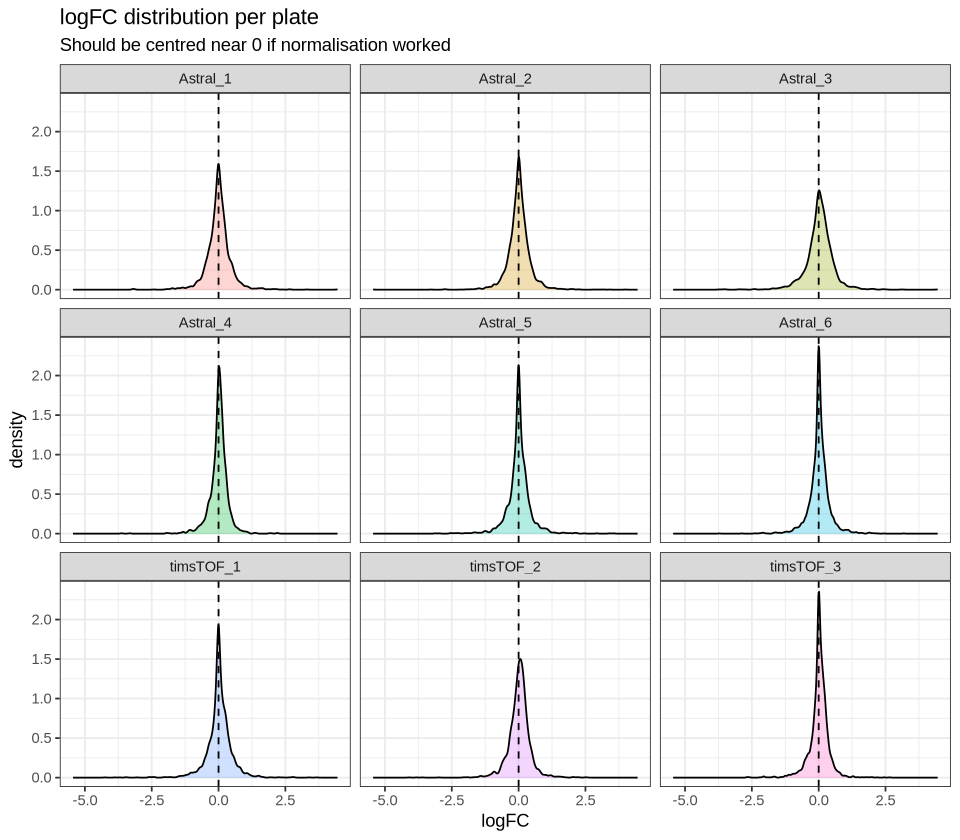

In [30]:
bind_rows(results_per_plate, .id = "plate") %>%
    filter(!is.na(logFC)) %>%
    ggplot(aes(x = logFC, fill = plate)) +
    geom_density(alpha = 0.3) +
    geom_vline(xintercept = 0, linetype = "dashed") +
    facet_wrap(~plate) +
    labs(title = "logFC distribution per plate",
         subtitle = "Should be centred near 0 if normalisation worked") +
    theme_bw() +
    theme(legend.position = "none")

## 10.2 Overlap on a commonly quantified protein set

The overlap above is computed over all tested proteins, so part of the non-overlap reflects differences in which proteins each plate detected rather than differences in biological signal. To isolate the biological signal, the overlap is recomputed on a commonly quantified protein set: proteins observed in at least `MIN_CELL_PCT` of the cells within a plate, in at least `MIN_N_PLATES` plates.

The models are **not** refit. The existing integrated (`res_all`) and per-plate result tables are subset to this protein set, and the per-protein statistics (including the originally computed BH-adjusted p-values) are kept as they are. Only the protein set entering the overlap changes. If you would rather re-adjust the p-values over the reduced set, apply `p.adjust(pval, "BH")` to the filtered tables before plotting.

In [31]:
# Minimum completeness for a protein to enter the overlap comparison
MIN_CELL_PCT <- 0.25   # fraction of cells within a plate
MIN_N_PLATES <- 5      # number of plates that must pass

# Protein IDs observed in >= min_cell_pct of the cells within a plate,
# in >= min_n_plates plates. Computed on the aggregated protein assay.
well_observed_proteins <- function(qf,
                                   assay_name   = "proteins_medianPolish",
                                   col_plate    = COL_PLATE,
                                   min_cell_pct = MIN_CELL_PCT,
                                   min_n_plates = MIN_N_PLATES) {
    X      <- assay(qf[[assay_name]])
    meta   <- as.data.frame(colData(qf))
    plates <- levels(factor(meta[[col_plate]]))

    plate_comp <- sapply(plates, function(plate) {
        idx  <- which(meta[[col_plate]] == plate)
        m    <- X[, idx, drop = FALSE]
        comp <- rowMeans(!is.na(m))
        comp[rowSums(!is.na(m)) == 0] <- NA
        comp
    })

    passes <- plate_comp >= min_cell_pct
    keep   <- rowSums(passes, na.rm = TRUE) >= min_n_plates

    cat(sprintf("Completeness filter (%s):\n", assay_name))
    cat(sprintf("  Min. %% cells within plate : %.0f%%\n", min_cell_pct * 100))
    cat(sprintf("  Min. number of plates     : %d / %d\n", min_n_plates, length(plates)))
    cat(sprintf("  Proteins before           : %d\n", nrow(X)))
    cat(sprintf("  Proteins after            : %d  (%.1f%% retained)\n",
                sum(keep), 100 * mean(keep)))
    rownames(X)[keep]
}

# Non-destructive: use the pre-fit checkpoint to define the protein set
qf_ref        <- readRDS(file.path(QF_DIR, "qf_checkpoint.rds"))
keep_proteins <- well_observed_proteins(qf_ref)

Completeness filter (proteins_medianPolish):
  Min. % cells within plate : 25%
  Min. number of plates     : 5 / 9
  Proteins before           : 6628
  Proteins after            : 2153  (32.5% retained)


In [32]:
# Subset the existing results to the commonly quantified proteins (no refit)
res_all_filt <- res_all %>% filter(protein %in% keep_proteins)
results_per_plate_filt <- lapply(results_per_plate, function(df)
    df %>% filter(protein %in% keep_proteins))

n_sig <- function(df) sum(df$adjPval < FDR_THRESHOLD & abs(df$logFC) > FC_THRESHOLD, na.rm = TRUE)

cat(sprintf("Integrated significant : %d -> %d after filtering\n",
            n_sig(res_all), n_sig(res_all_filt)))
cat("Per-plate significant (before -> after):\n")
for (p in names(results_per_plate)) {
    cat(sprintf("  %-14s %d -> %d\n", p,
                n_sig(results_per_plate[[p]]), n_sig(results_per_plate_filt[[p]])))
}

Integrated significant : 508 -> 330 after filtering
Per-plate significant (before -> after):
  Astral_1       456 -> 384
  Astral_2       567 -> 385
  Astral_3       420 -> 370
  Astral_4       169 -> 160
  Astral_5       287 -> 270
  Astral_6       336 -> 278
  timsTOF_1      355 -> 328
  timsTOF_2      380 -> 322
  timsTOF_3      257 -> 233


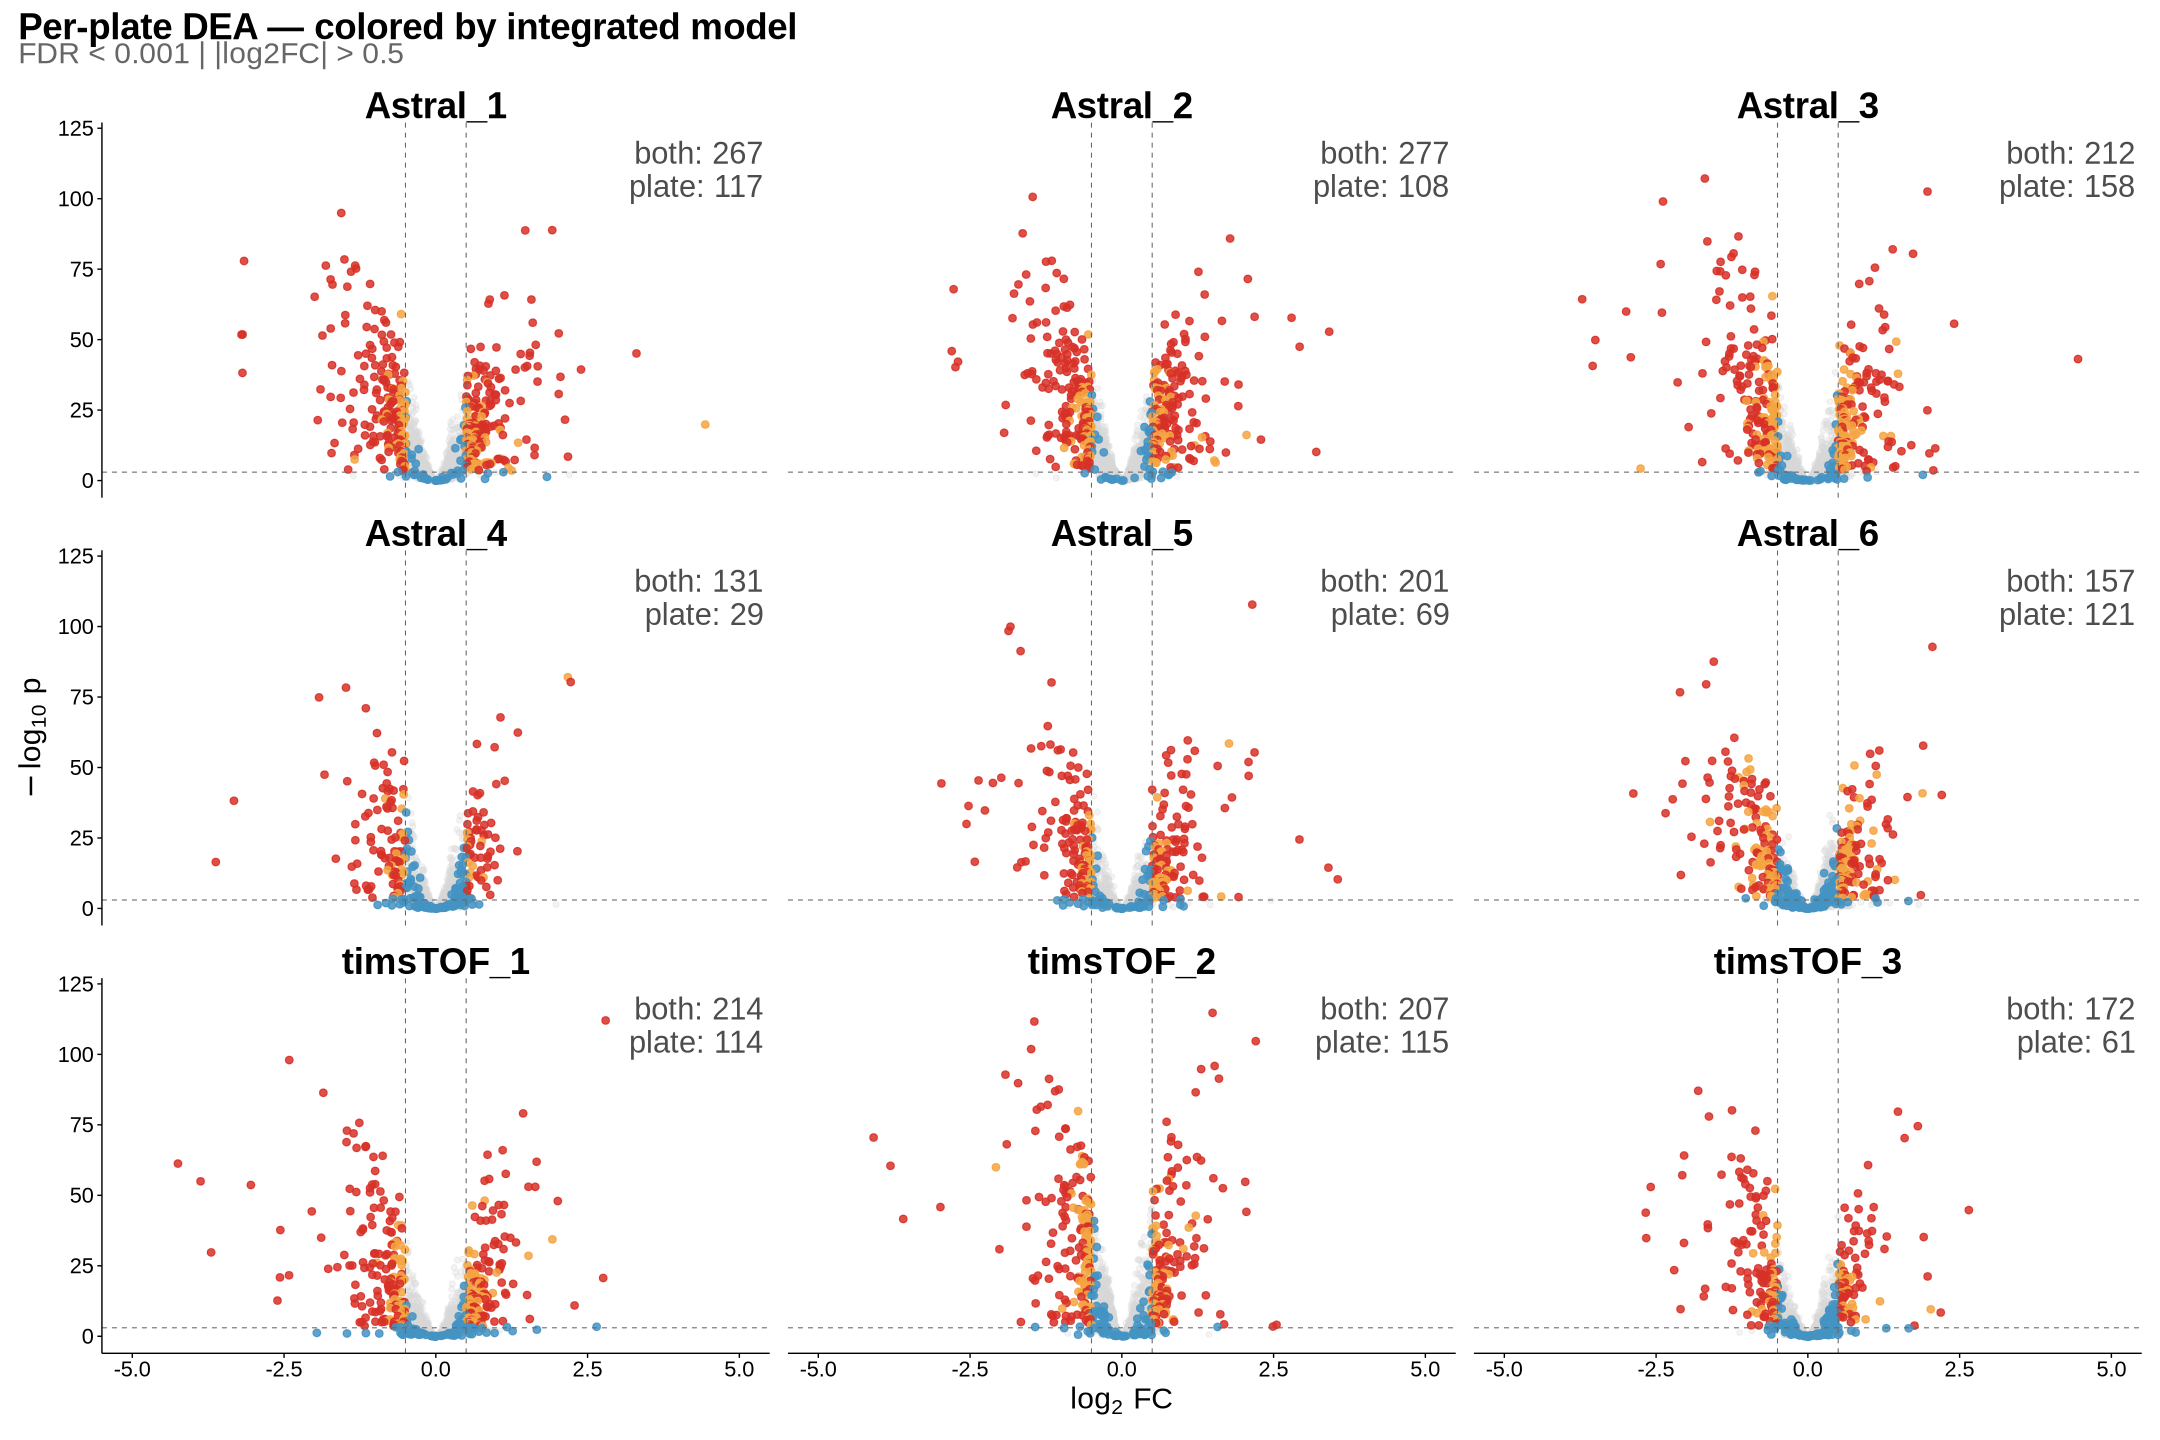

In [33]:
plot_volcano_grid_per_plate(
    results_per_plate = results_per_plate_filt,
    res_integrated    = res_all_filt,
    fdr_threshold     = FDR_THRESHOLD,
    fc_threshold      = FC_THRESHOLD,
    save_dir          = FIG_OUT,
    filename          = "volcano_grid_per_plate_filtered",
    show              = TRUE
)

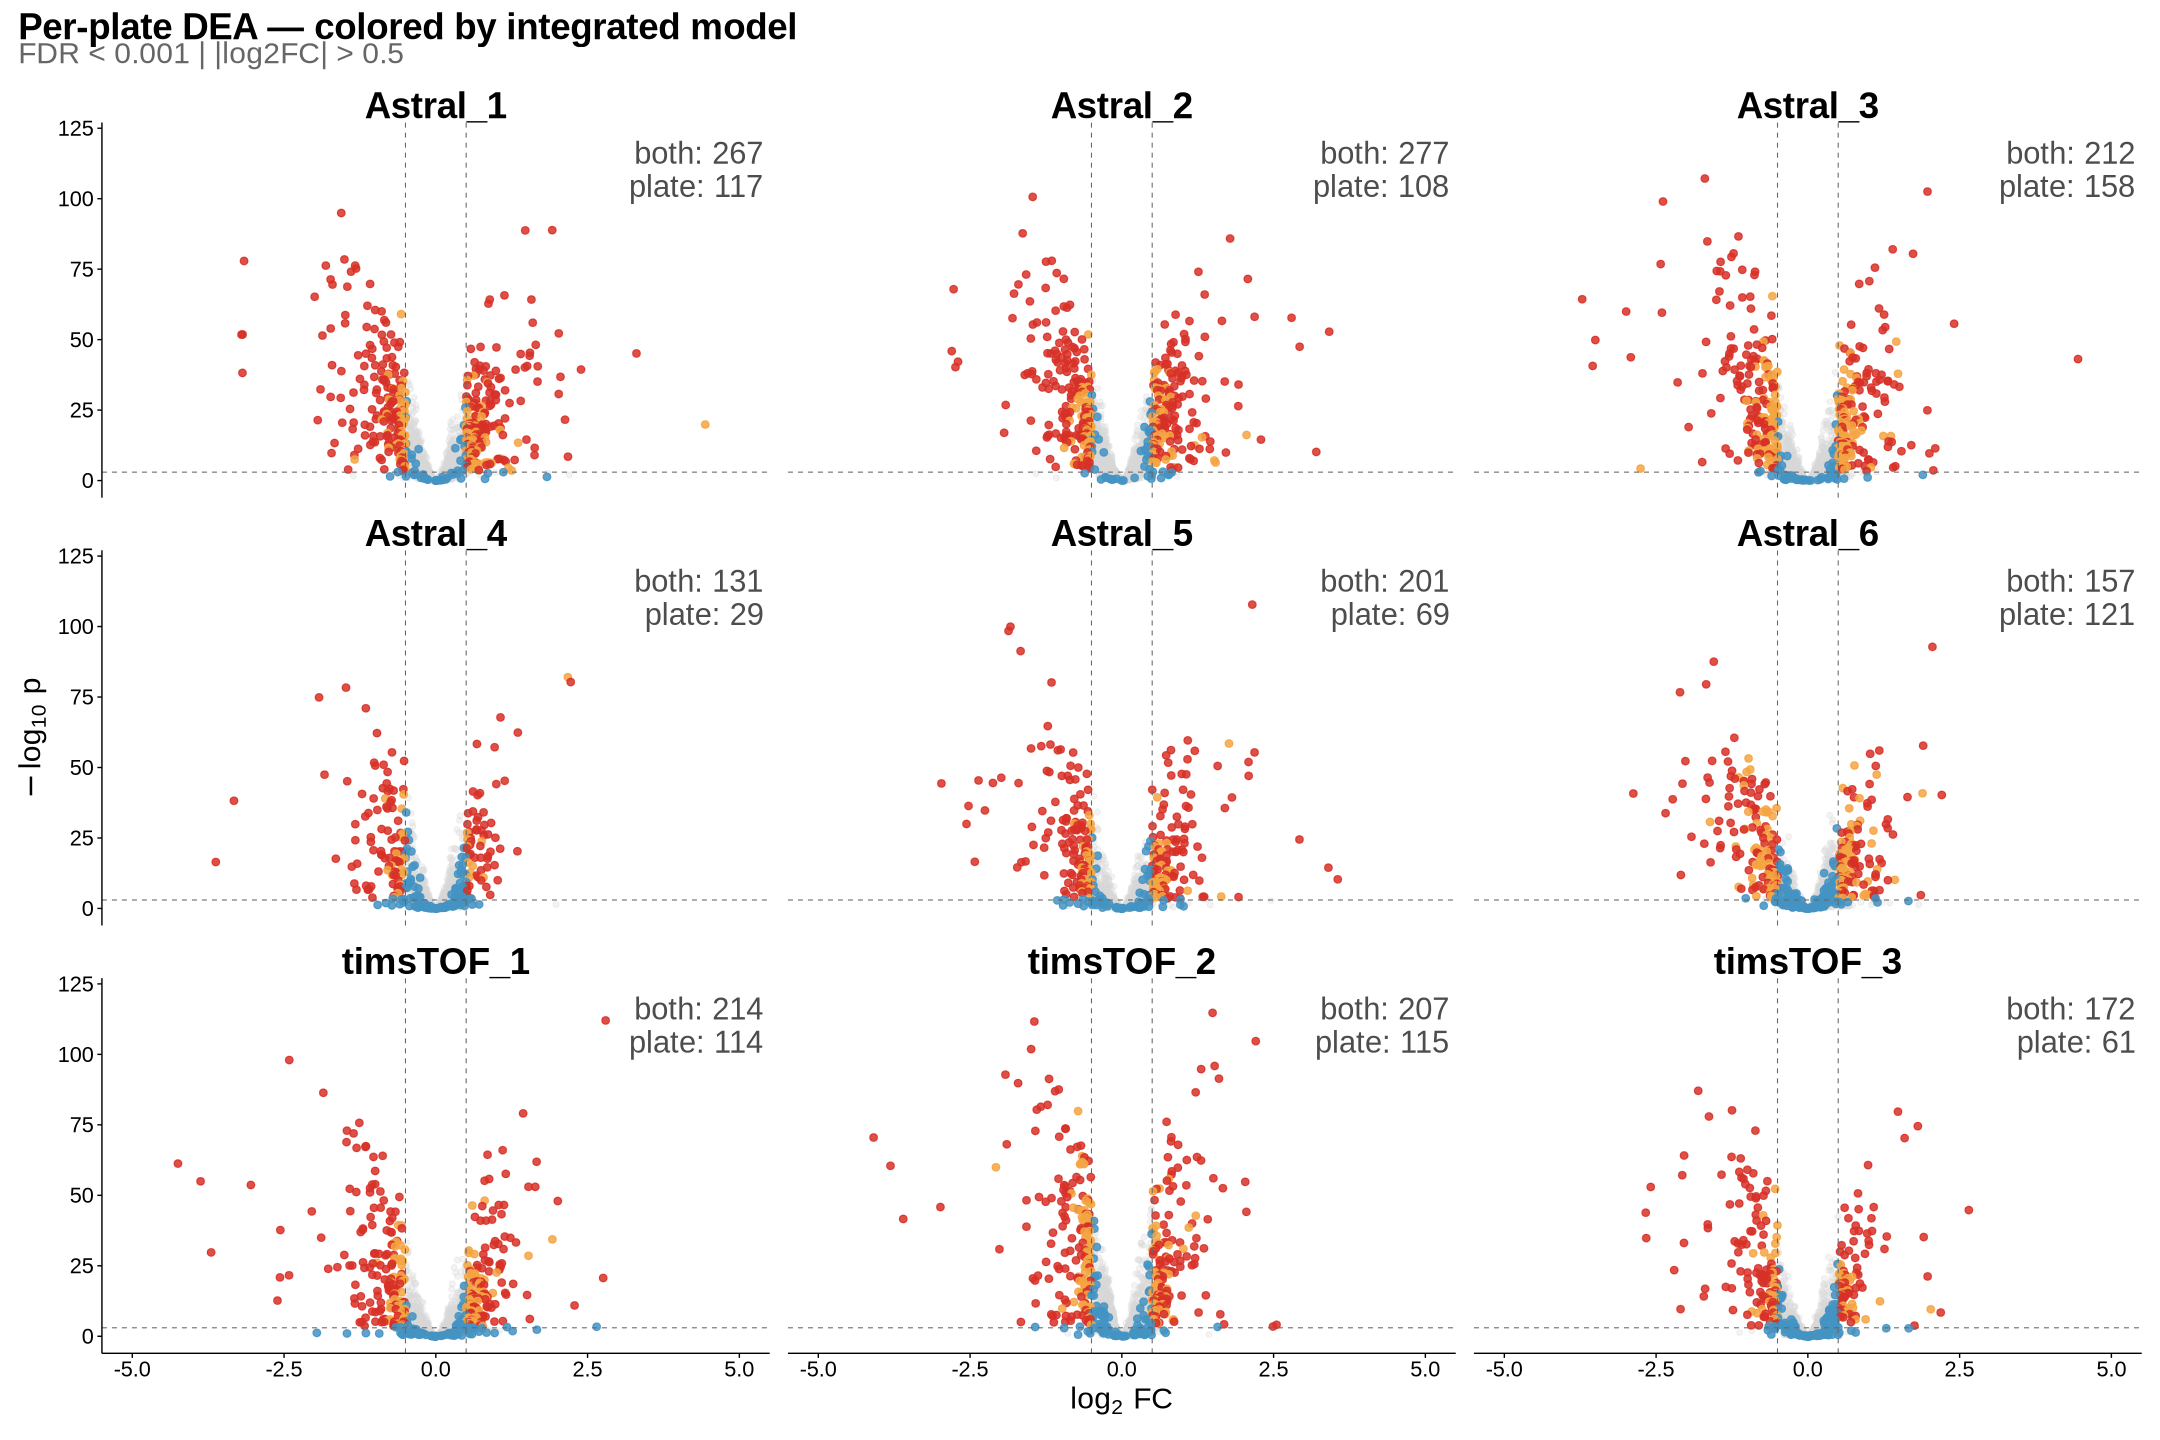

In [34]:
plot_volcano_grid_per_plate(
    results_per_plate = results_per_plate_filt,
    res_integrated    = res_all_filt,
    fdr_threshold     = FDR_THRESHOLD,
    fc_threshold      = FC_THRESHOLD,
    save_dir          = FIG_OUT,
    filename          = "volcano_grid_per_plate_filtered",
    show              = TRUE
)


Upregulated proteins per model:
Integrated   Astral_1   Astral_2   Astral_3   Astral_4   Astral_5   Astral_6 
       155        189        175        185         64        129        134 
 timsTOF_1  timsTOF_2  timsTOF_3 
       157        147         96 

Downregulated proteins per model:
Integrated   Astral_1   Astral_2   Astral_3   Astral_4   Astral_5   Astral_6 
       175        195        210        185         96        141        144 
 timsTOF_1  timsTOF_2  timsTOF_3 
       171        175        137 

Differentiallyregulated proteins per model:
Integrated   Astral_1   Astral_2   Astral_3   Astral_4   Astral_5   Astral_6 
       330        384        385        370        160        270        278 
 timsTOF_1  timsTOF_2  timsTOF_3 
       328        322        233 


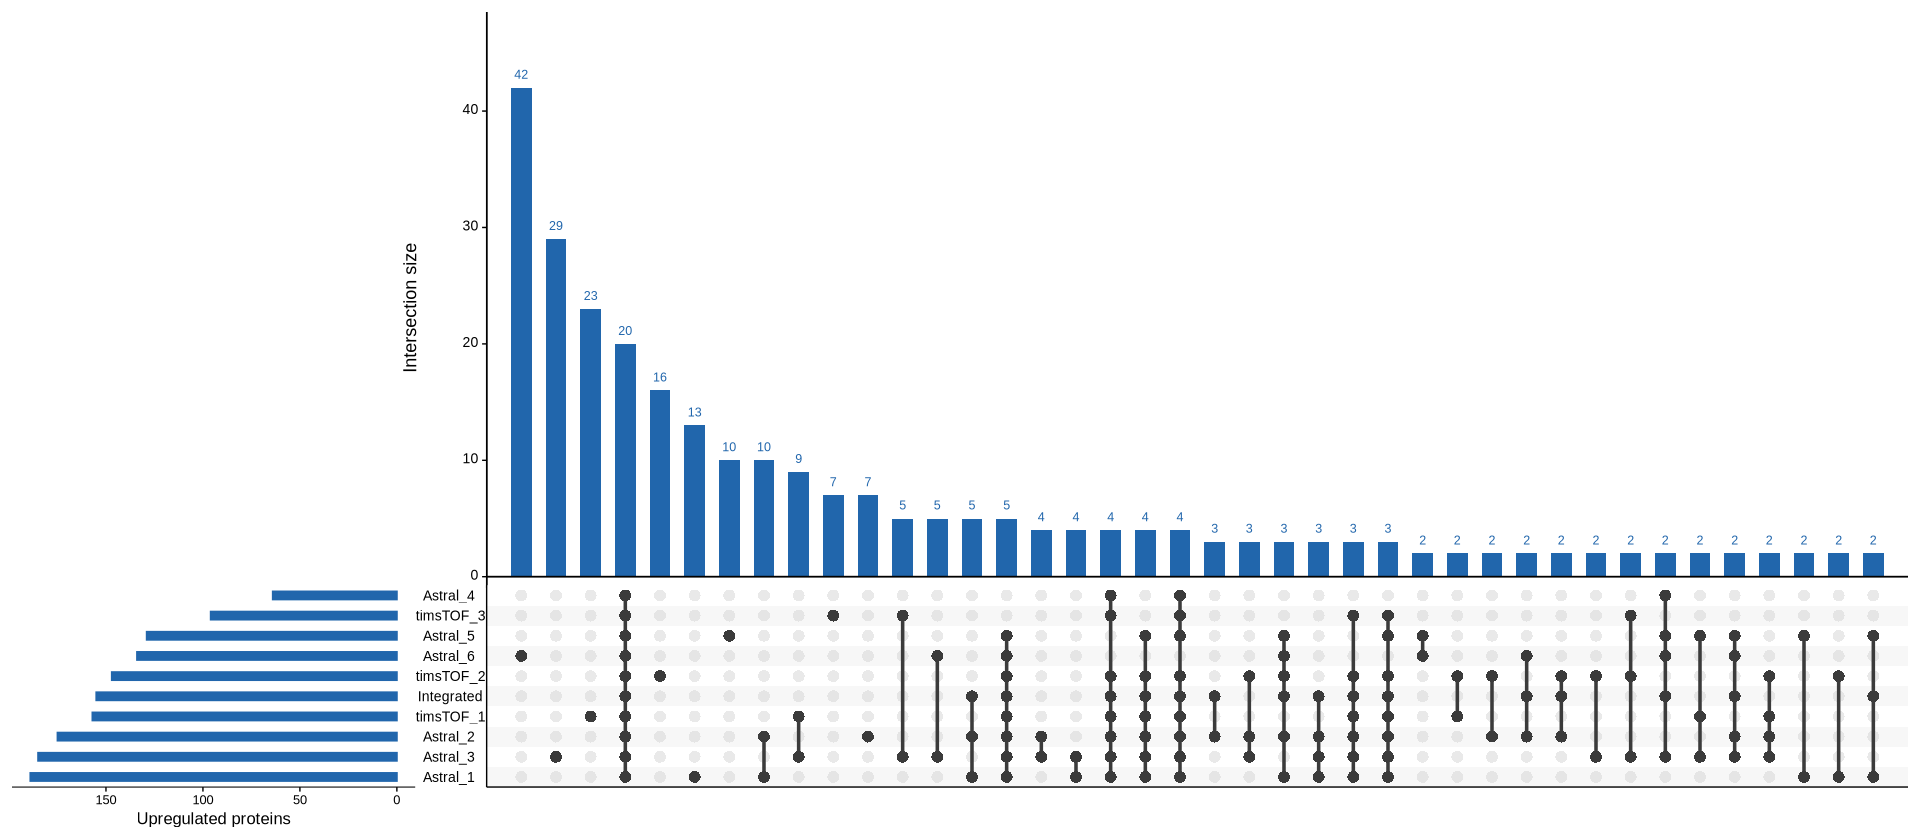

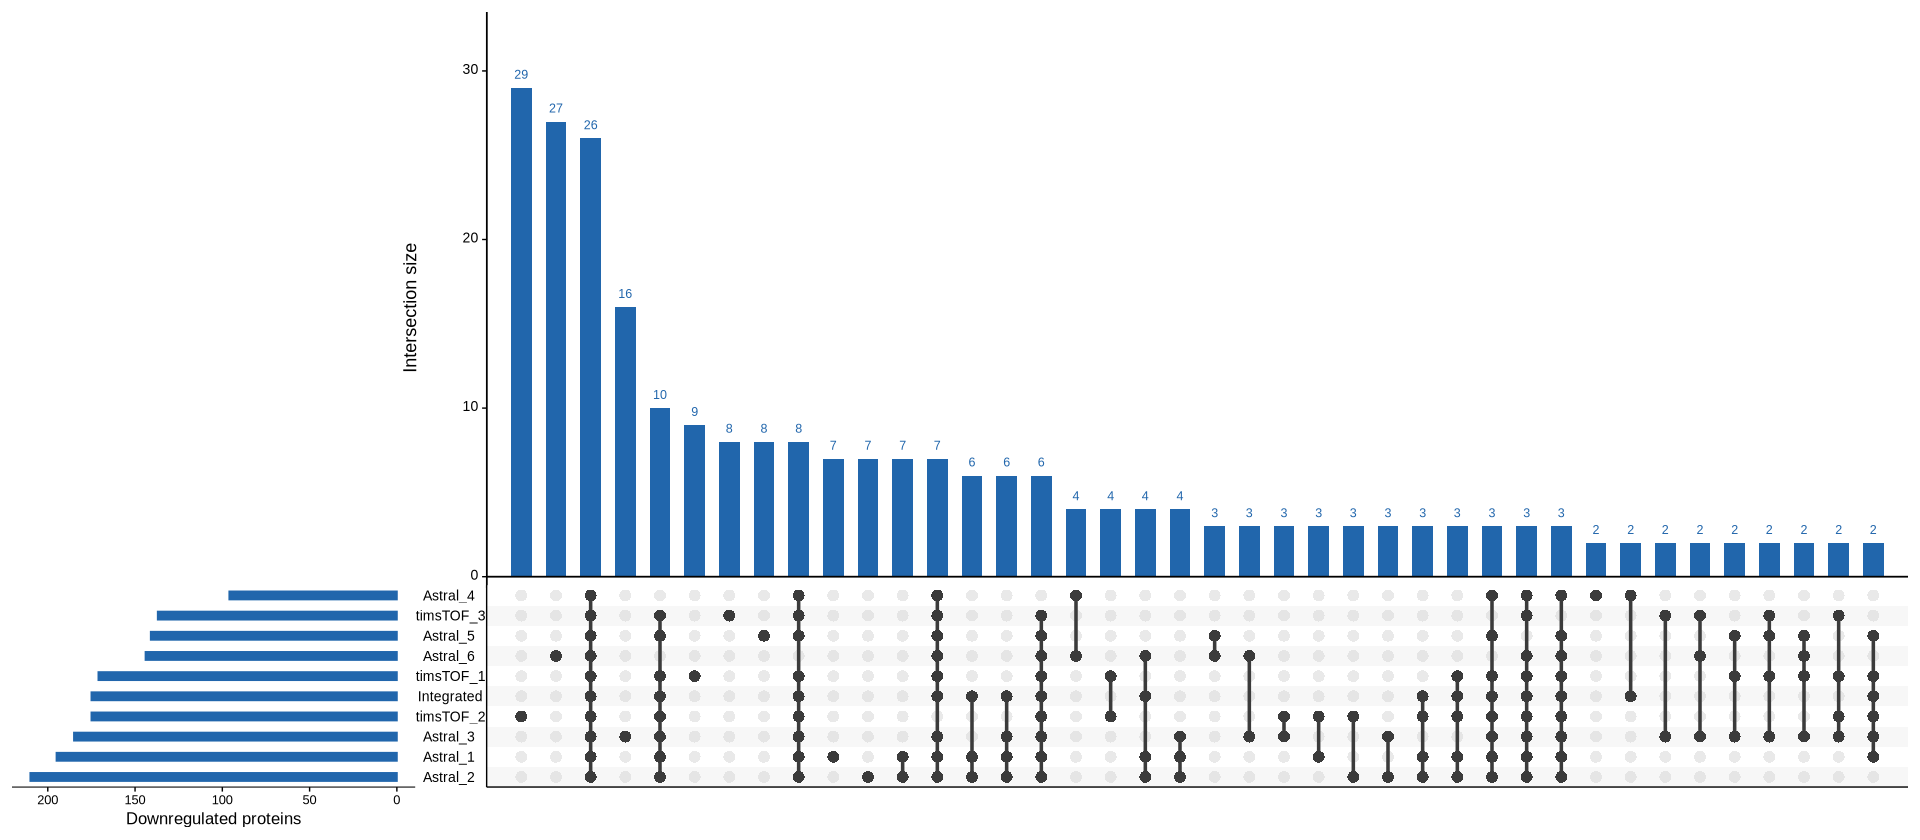

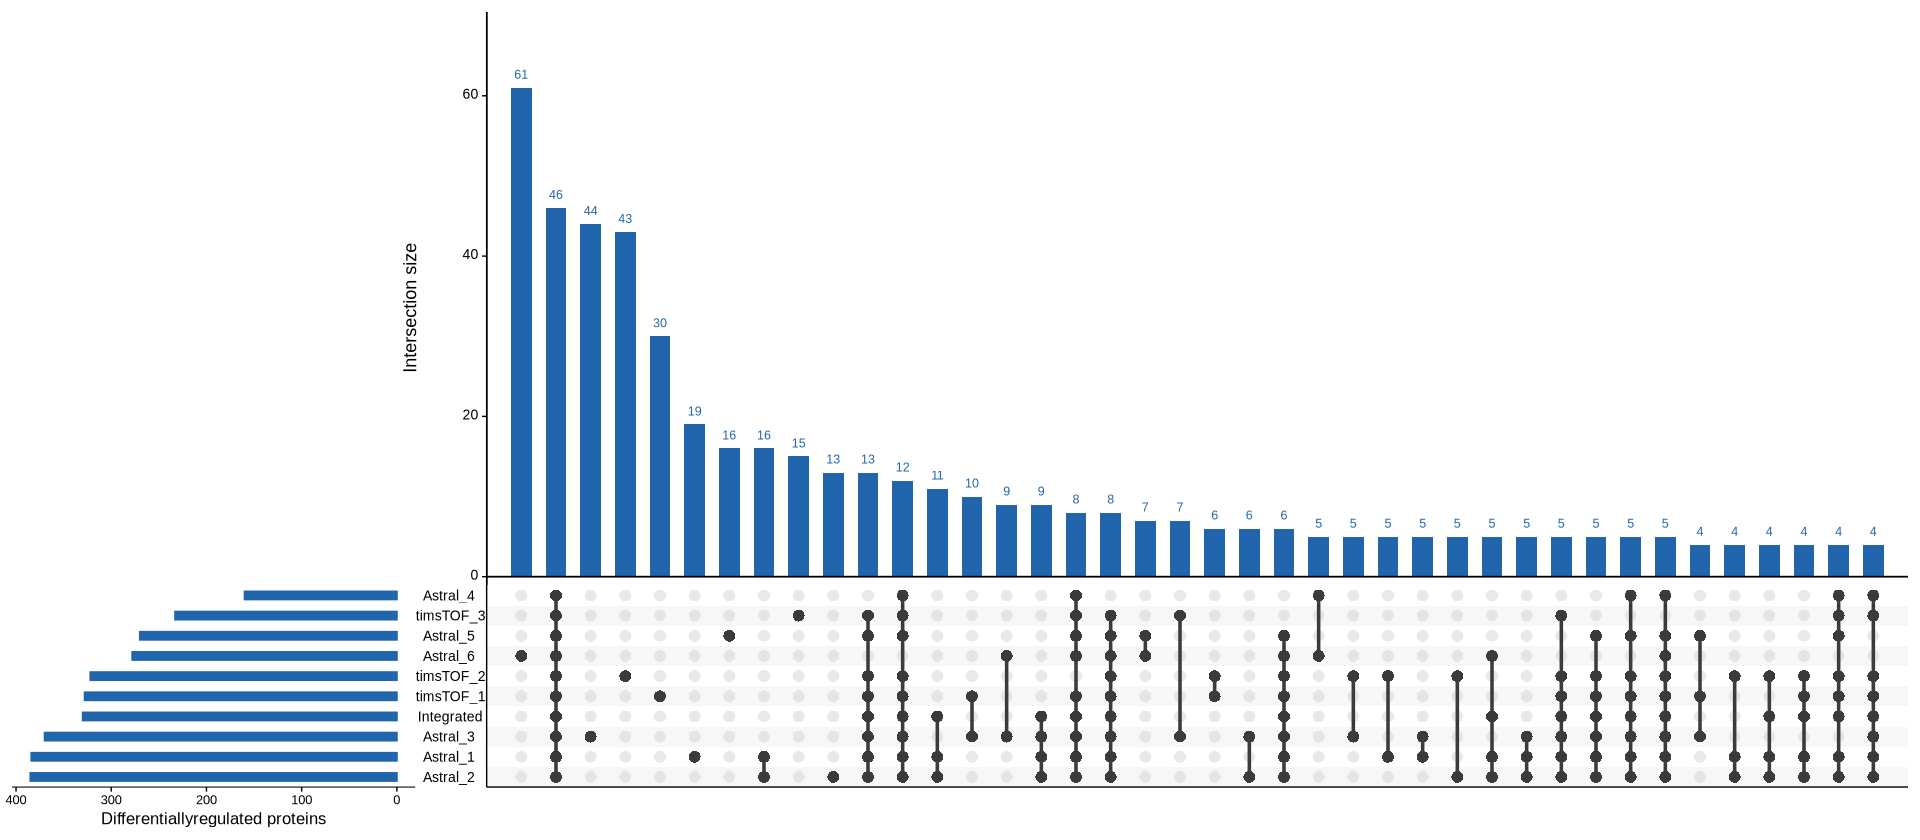

In [35]:
plot_upset_per_plate(
    results_per_plate = results_per_plate_filt,
    res_integrated    = res_all_filt,
    fdr_threshold     = FDR_THRESHOLD,
    fc_threshold      = FC_THRESHOLD,
    save_dir          = FIG_OUT,
    filename          = "upset_per_plate_filtered",
    show              = TRUE
)

logFC correlation computed on 798 proteins (union of significant)


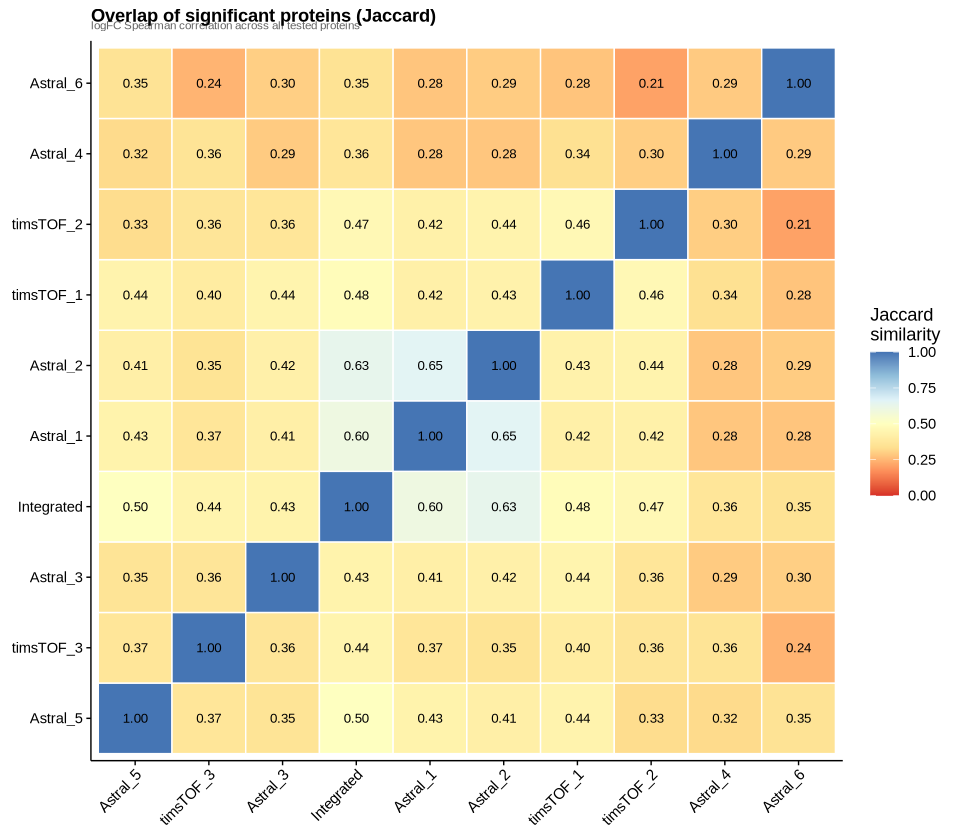

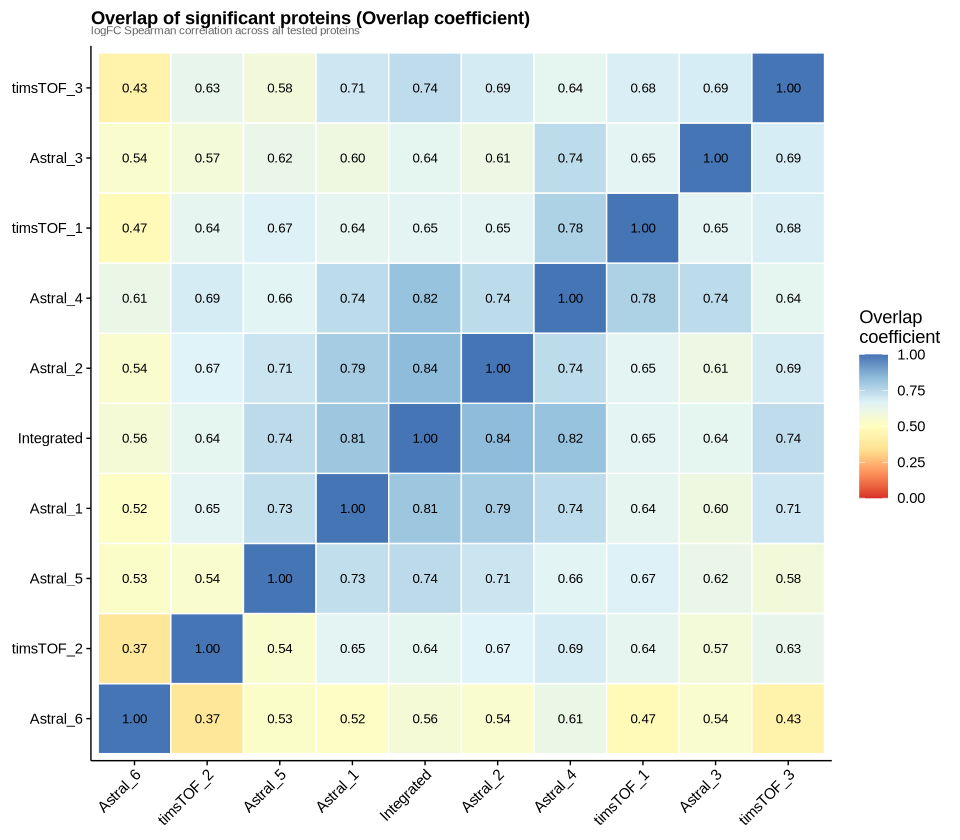

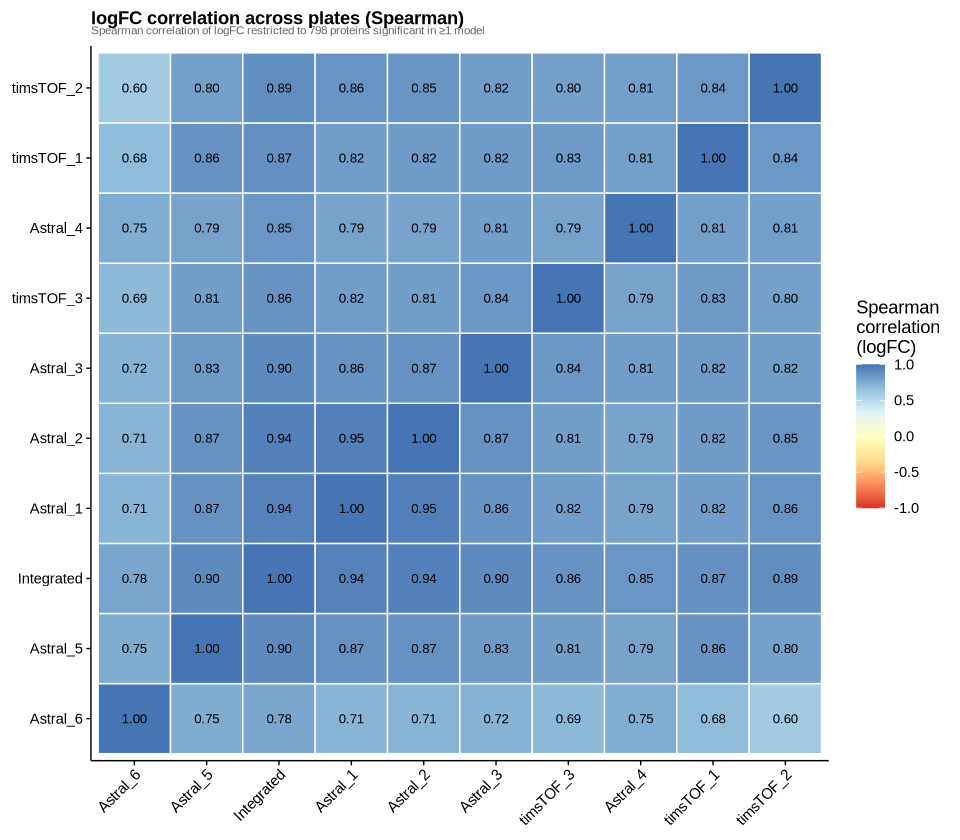

In [36]:
for (m in c("jaccard", "overlap", "logfc_cor")) {
    plot_overlap_heatmap(
        results_per_plate_filt, res_all_filt,
        metric   = m,
        save_dir = FIG_OUT,
        filename = sprintf("overlap_heatmap_%s_filtered.png", m)
    )
}

### 10.3 Per-plate volcanos colored by cross-lab overlap

The panels below colour each protein by how many plates it is significant in, rather than by overlap with the integrated model:

- **Hit in all labs** (purple): significant in every plate.
- **Hit in few labs** (red): significant in more than one plate but not all.
- **Hit in one lab** (orange): significant in exactly one plate.
- **Other** (grey): not significant in that plate.

A protein is coloured by its category only in the plates where it is itself significant. The y-axis is `-log10(adjPval)`. This is shown for both the unfiltered per-plate results and the commonly quantified (filtered) set from 10.2, so the effect of the identification set on the overlap is visible.

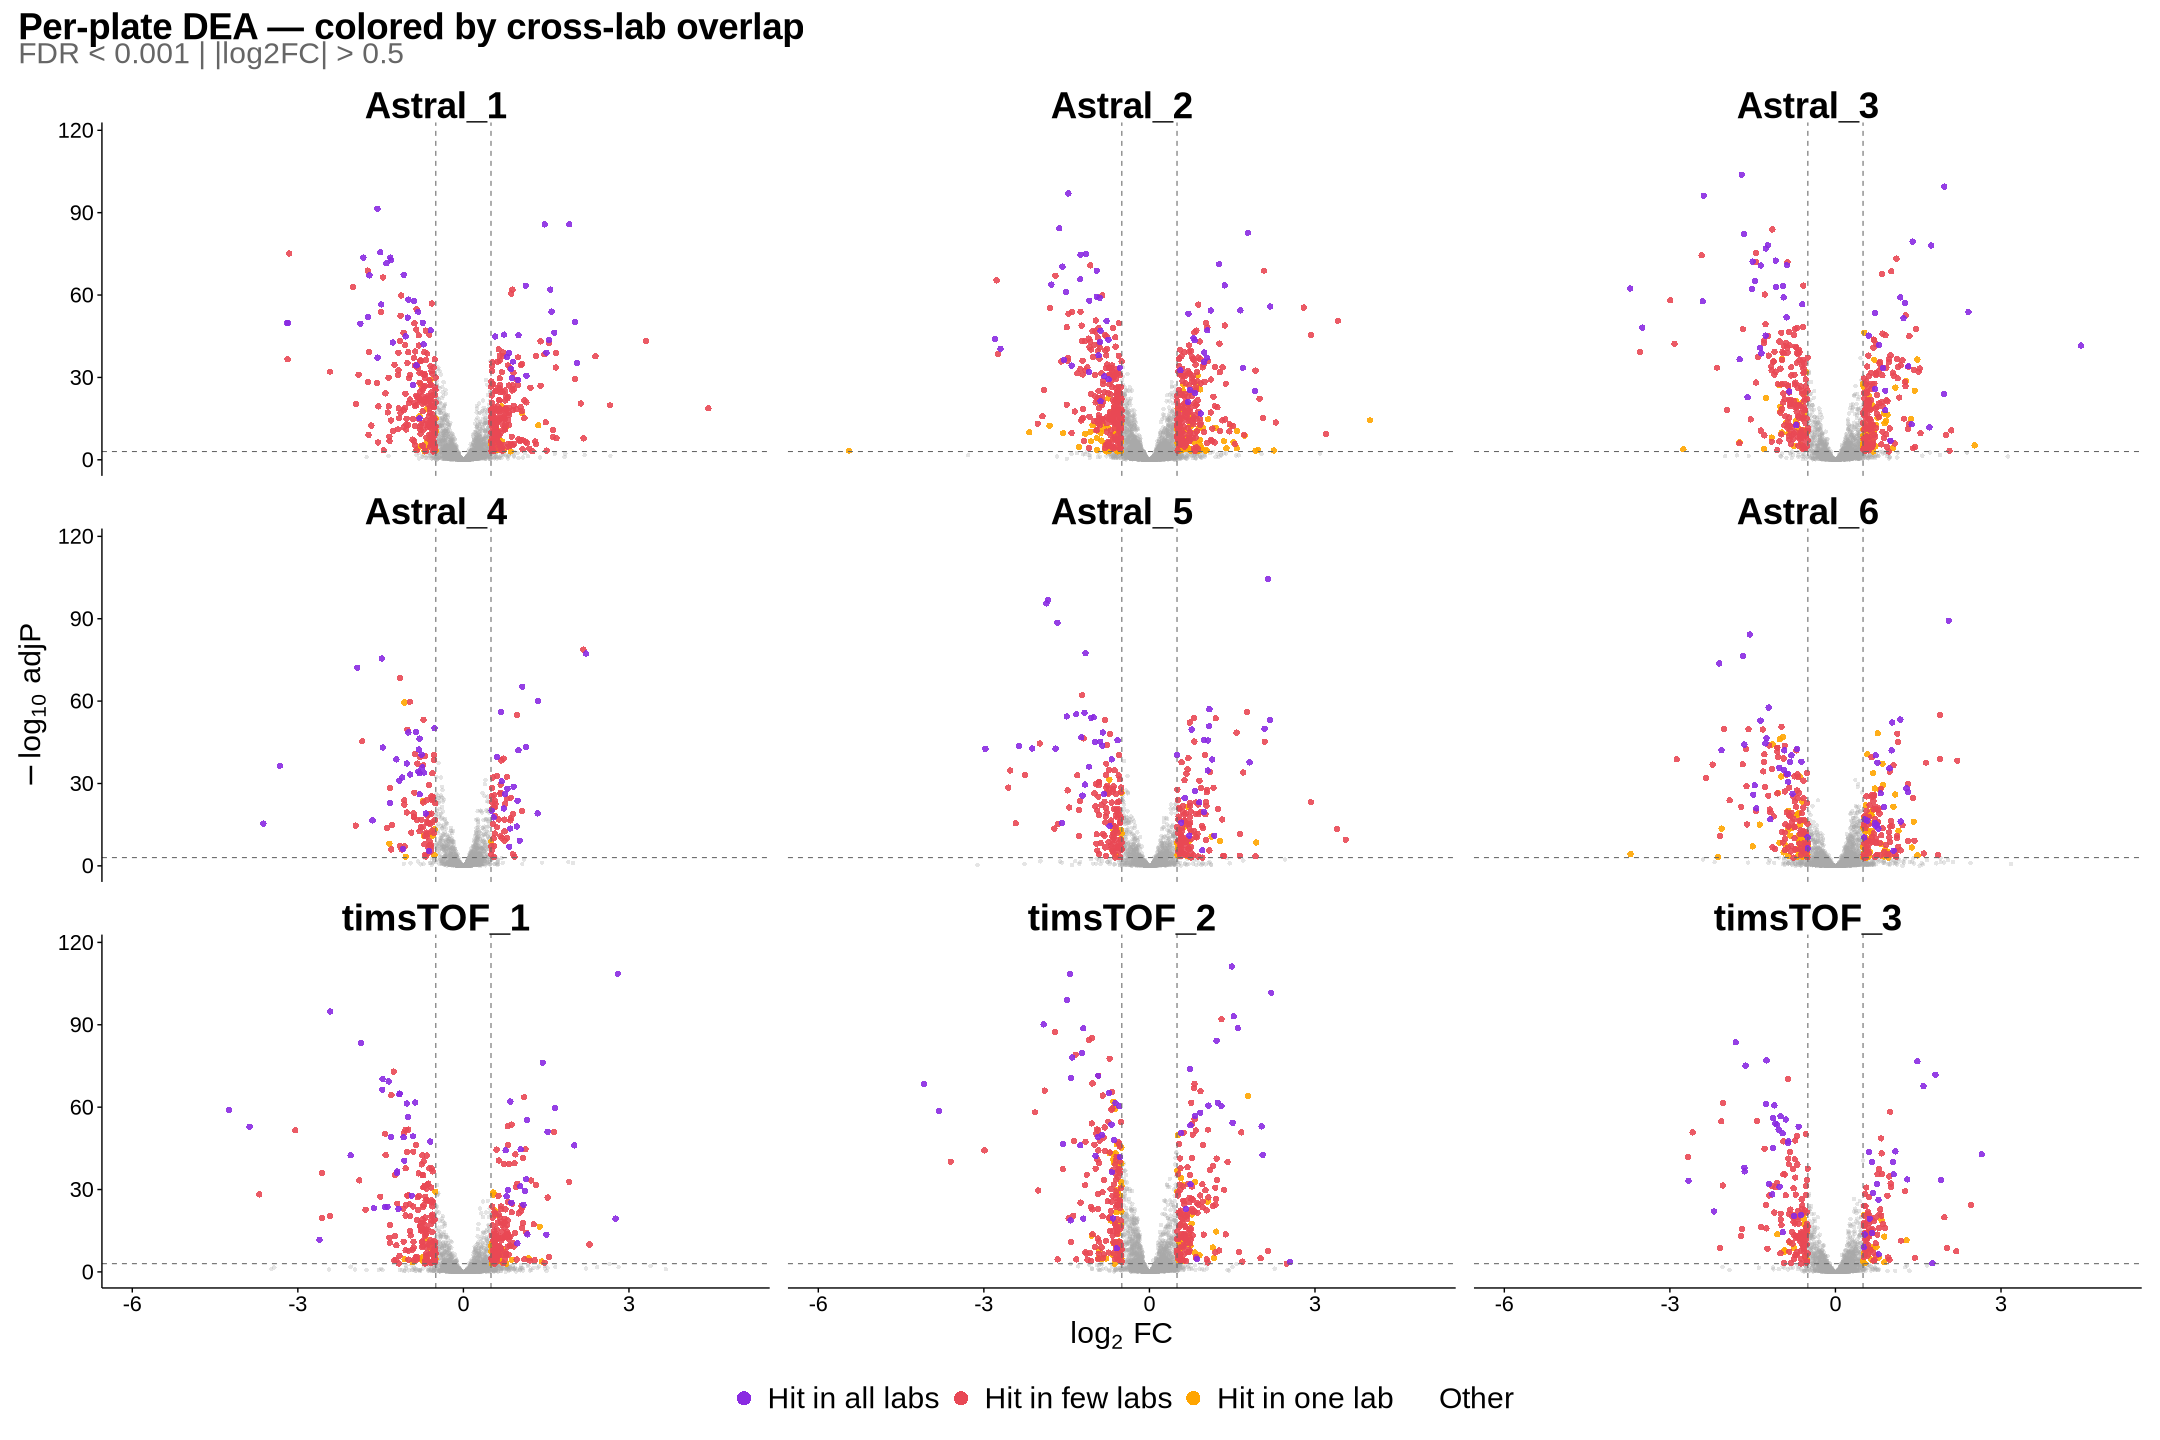

In [37]:
# Unfiltered per-plate results
plot_volcano_grid_per_plate_overlap(
    results_per_plate = results_per_plate,
    fdr_threshold     = FDR_THRESHOLD,
    fc_threshold      = FC_THRESHOLD,
    save_dir          = FIG_OUT,
    filename          = "volcano_grid_per_plate_overlap",
    show              = TRUE
)

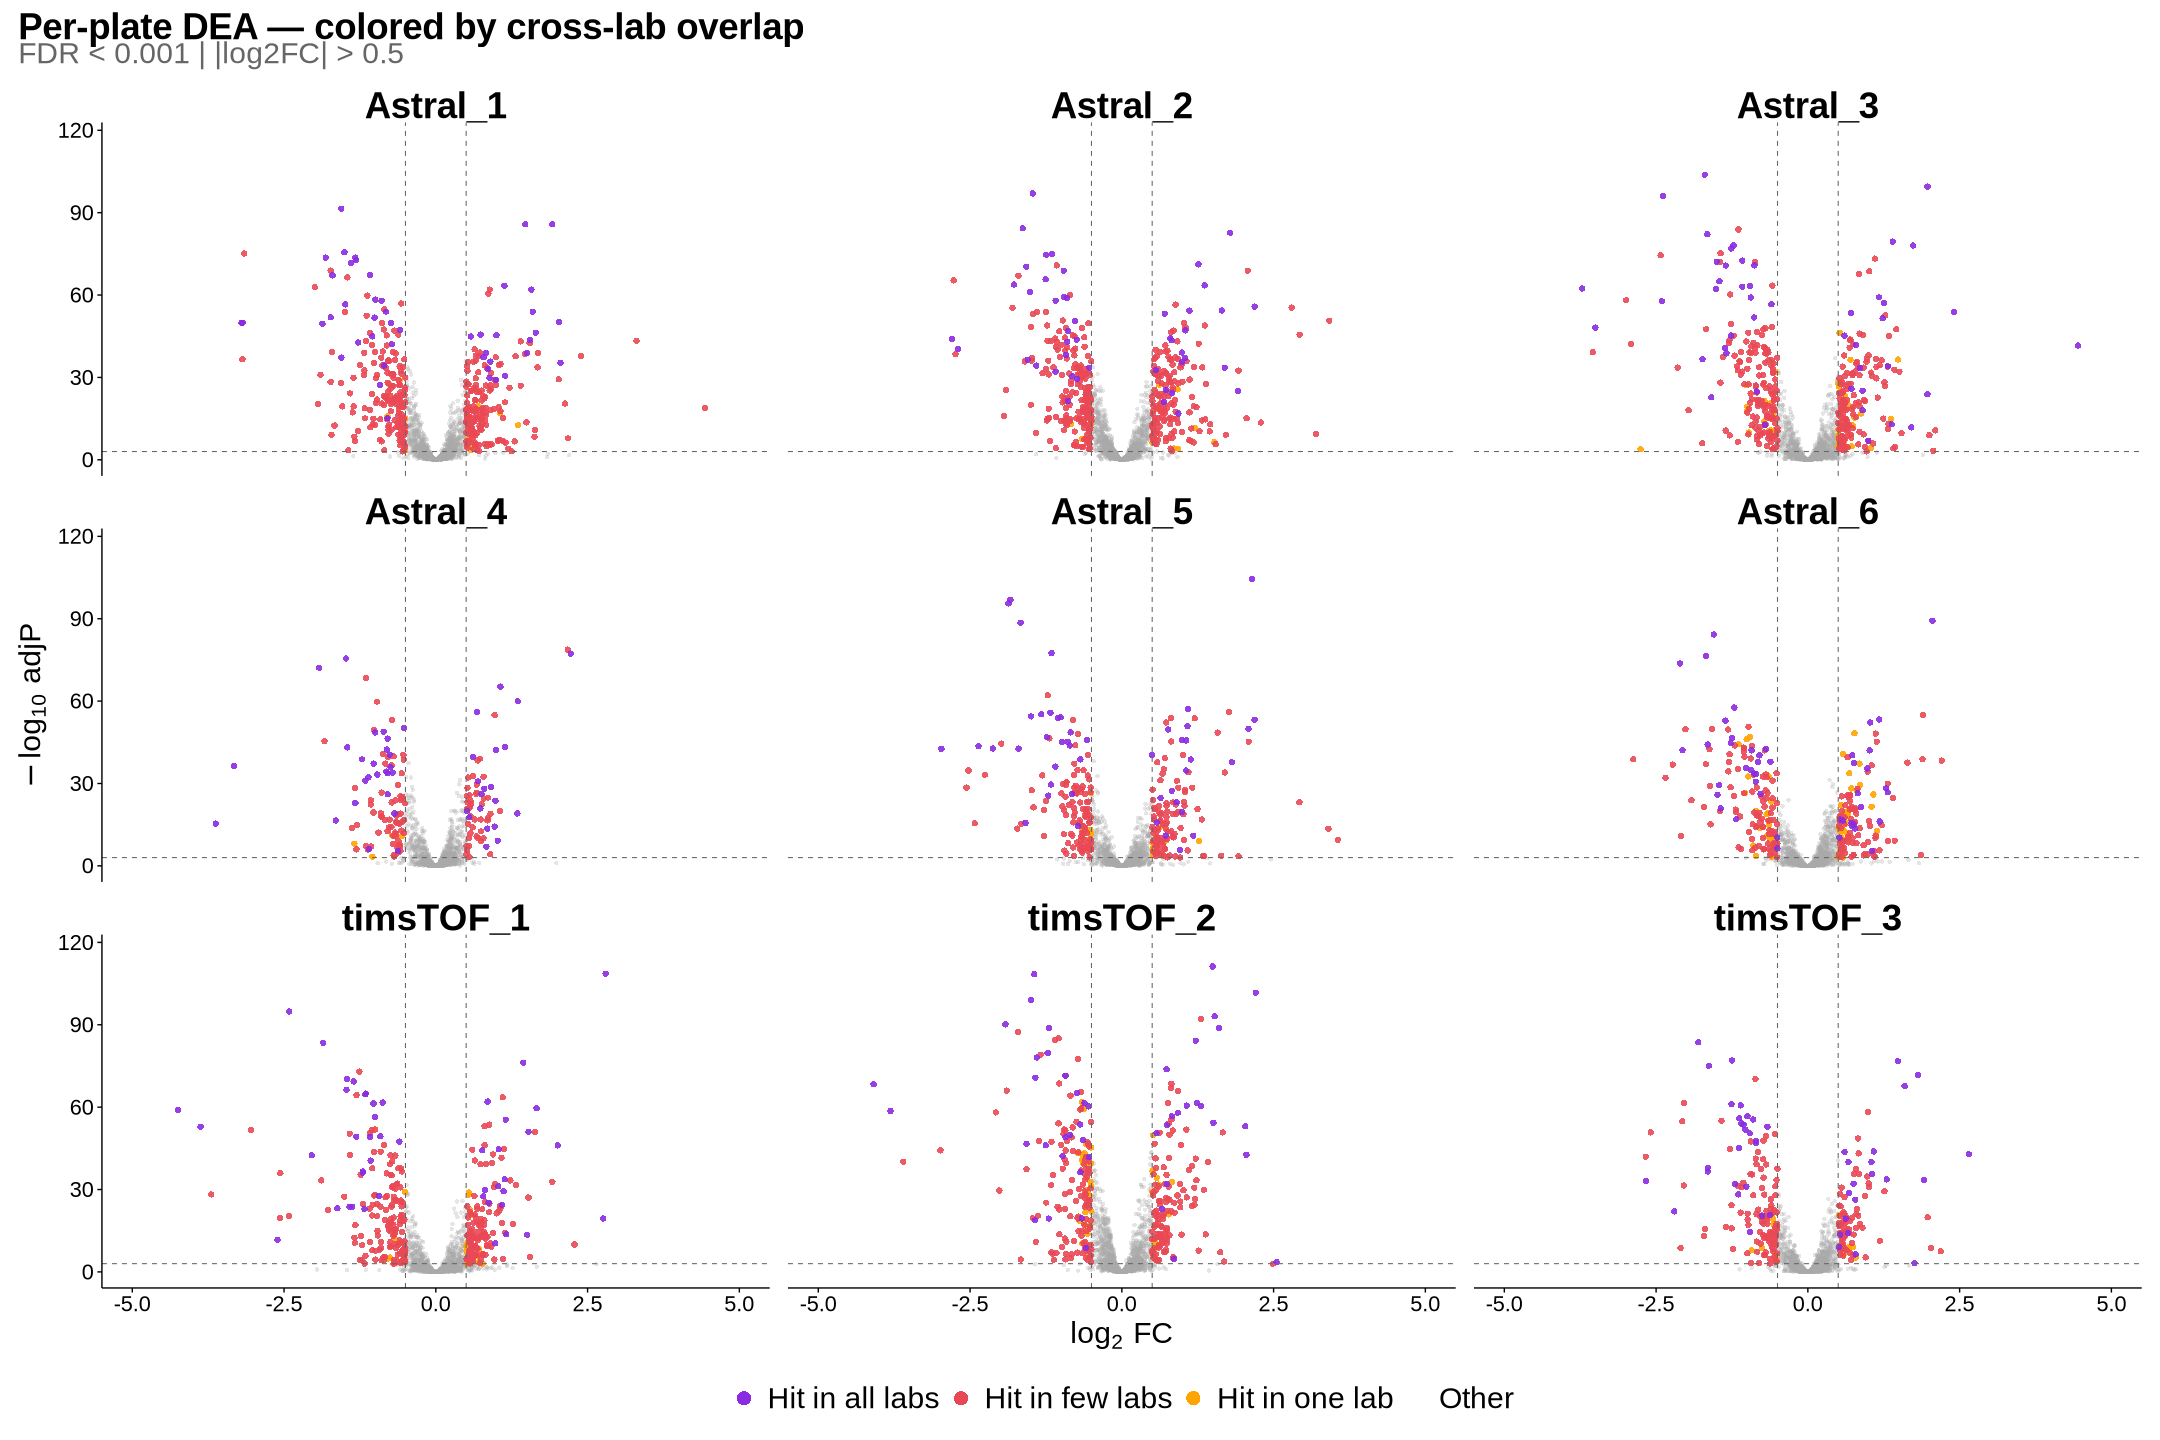

In [38]:
# Commonly quantified (filtered) per-plate results from section 10.2
plot_volcano_grid_per_plate_overlap(
    results_per_plate = results_per_plate_filt,
    fdr_threshold     = FDR_THRESHOLD,
    fc_threshold      = FC_THRESHOLD,
    save_dir          = FIG_OUT,
    filename          = "volcano_grid_per_plate_overlap_filtered",
    show              = TRUE
)